In [270]:
%reset -f
%load_ext autoreload
%autoreload 2

import os
import time
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import glob
import math
from sklearn.linear_model import LinearRegression
import figurefirst as fifi
sys.path.append('../utils_2')
import figure_functions as ff
from pybounds import SlidingEmpiricalObservabilityMatrix, SlidingFisherObservability, colorline
sys.path.append('../model')
from drone_model_with_PWM import DroneSimulator
from drone_model_with_PWM import DroneModel
from drone_model_with_PWM import DroneParameters
sys.path.append('../EKF')
from ekf import ekf as EKF
import pynumdiff
from scipy import signal
sys.path.append('../trajectories')
from trajectory_gen import TrajectoryGenerator
from IPython.display import display,SVG
# from drone_model_body_level import DroneSimulator

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Import Data

In [271]:
condition = 'flying' #['walking', 'flying']
motif = 'sine' #['p2p', 'p2p_con_yaw', 'acc', 'sine']
path = '/home/austinlopez/Drone_AFRL/CSV/BIG_BUG_DATA'
all_files = glob.glob(path + "/" + condition + "/" + motif + "/*.csv")
data = {}
for filename in all_files:
    df = pd.read_csv(filename,index_col=None,header=0)
    # set data dictionary based on filename after the string '__'
    key = filename.split('__')[-1].split('.')[0]
    # remove the next 18 characters from the key name then replace '_slash_' with '/'
    key = key[6:].replace('_slash_', '/')
    data[key] = df

for key in data.keys():
    print(key)

mavros/imu/data
optic_flow/global/mean/y
trisonica_body_level
mavros/imu/data_raw
optic_flow/wind_sensor/mean/y
optic_flow/wind_sensor/mean/x
mavros/rc/out
mavros/setpoint_raw/local
mavros/local_position/velocity_body
trisonica
mavros/imu/mag
optic_flow/camera/mean/y
trisonica_global
mavros/local_position/velocity_local
mavros/vision_pose/pose
optic_flow/global/mean/x
optic_flow/camera/mean/x
mavros/local_position/pose
mavros/rc/in
rosout


# useful functions to have

In [272]:
def quaternion_to_euler(x, y, z, w):
    """
    input: x, y, z, w
    output: R, P, Y
    """
    t0 = +2.0 * (w * x + y * z)
    t1 = +1.0 - 2.0 * (x * x + y * y)
    R = math.degrees(math.atan2(t0, t1))

    t2 = +2.0 * (w * y - z * x)
    t2 = +1.0 if t2 > +1.0 else t2
    t2 = -1.0 if t2 < -1.0 else t2
    P = math.degrees(math.asin(t2))

    t3 = +2.0 * (w * z + x * y)
    t4 = +1.0 - 2.0 * (y * y + z * z)
    Y = math.degrees(math.atan2(t3, t4))

    return R, P, Y

# function that interpolates data based on two time arrays using numpy
def interpolate_data(time1, data1, time2):
    """
    input: time1 (interp from), data1 (interp from), time2 (interp to)
    output: interpolated data2
    """
    return np.interp(time2, time1, data1)

# function that takes in data frame and gives out time array based on the columns secs and nsecs
def time_array(data):
    "input: data frame with columns secs and nsecs"
    "output: array of time in seconds"
    time = []
    for i in range(len(data)):
        time.append(data['secs'][i] + data['nsecs'][i] * 1e-9)

    return time

def high_pass_filter(data, dt, cut_off_freq):
    """
    input: data, dt, cut_off_freq
    output: data_filtered
    """
    # Create the high pass filter
    b, a = signal.butter(1, cut_off_freq, 'high', fs=1/dt)
    
    # Apply the high pass filter
    data_filtered = signal.filtfilt(b, a, data)
    
    return data_filtered

def low_pass_filter(data, dt, cut_off_freq):
    """
    input: data, dt, cut_off_freq
    output: data_filtered
    """
    # Create the high pass filter
    b, a = signal.butter(1, cut_off_freq, 'low', fs=1/dt)
    
    # Apply the high pass filter
    data_filtered = signal.filtfilt(b, a, data)
    
    return data_filtered

import numpy as np
import pandas as pd
from scipy.stats import zscore

def remove_outliers(data, method='iqr', threshold=1.5):
    """
    Replaces outliers with the median of their column, preserving original shape and returning a NumPy array.

    Parameters:
        data (array-like or DataFrame): Input data (1D or 2D).
        method (str): 'iqr' or 'zscore'.
        threshold (float): Threshold for detecting outliers.
                           - IQR: commonly 1.5
                           - Z-score: commonly 3.0

    Returns:
        NumPy array with outliers replaced by column median, matching original dimensions.
    """
    original_data = np.asarray(data)
    is_1d = original_data.ndim == 1

    # Convert to DataFrame
    if is_1d:
        df = pd.DataFrame({'value': original_data})
    else:
        df = pd.DataFrame(original_data)

    processed = df.copy()

    if method == 'iqr':
        for col in processed.columns:
            Q1 = processed[col].quantile(0.25)
            Q3 = processed[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - threshold * IQR
            upper_bound = Q3 + threshold * IQR
            median = processed[col].median()
            processed[col] = processed[col].apply(lambda x: median if x < lower_bound or x > upper_bound else x)
    elif method == 'zscore':
        zscores = np.abs(zscore(processed))
        for i, col in enumerate(processed.columns):
            median = processed[col].median()
            processed.loc[zscores[:, i] > threshold, col] = median
    else:
        raise ValueError("Method must be 'iqr' or 'zscore'")

    result = processed.to_numpy()
    return result.flatten() if is_1d else result


# Ground truth Mocap

In [273]:
mocap_time = data['mavros/local_position/pose']['rosbagTimestamp']/1e9/2
mocap_dt = np.mean(np.diff(mocap_time))
print('mocap_dt:', 1/mocap_dt)
mocap_Roll, mocap_Pitch, mocap_Yaw = [], [], []
for i in range(len(data['mavros/local_position/pose'])):
    R, P, Y = quaternion_to_euler(data['mavros/local_position/pose']['x.1'][i],
                                  data['mavros/local_position/pose']['y.1'][i],
                                  data['mavros/local_position/pose']['z.1'][i],
                                  data['mavros/local_position/pose']['w'][i])
    mocap_Roll.append(R)
    mocap_Pitch.append(P)
    mocap_Yaw.append(Y)


mocap_X = data['mavros/local_position/pose']['x']
mocap_Y = data['mavros/local_position/pose']['y']
mocap_Z = data['mavros/local_position/pose']['z']

mocap_time_shifted = mocap_time - mocap_time[0]
# take the derivative of the mocap data to get the velocities

smooth_params = [10, 0.1]
mocap_X_hat, mocap_X_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_X, mocap_dt, smooth_params, options={'iterate': False})
mocap_Y_hat, mocap_Y_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Y, mocap_dt, smooth_params, options={'iterate': False})
mocap_Z_hat, mocap_Z_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Z, mocap_dt, smooth_params, options={'iterate': False})

mocap_Roll_hat, mocap_Roll_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Roll, mocap_dt, smooth_params, options={'iterate': False})
mocap_Pitch_hat, mocap_Pitch_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Pitch, mocap_dt, smooth_params, options={'iterate': False})
mocap_Yaw_hat, mocap_Yaw_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Yaw, mocap_dt, smooth_params, options={'iterate': False})

mocap_Roll = mocap_Roll_hat
mocap_Pitch = mocap_Pitch_hat
mocap_Yaw = mocap_Yaw_hat

mocap_Xdot_hat,mocap_X_ddot = pynumdiff.smooth_finite_difference.butterdiff(mocap_X_dot, mocap_dt, smooth_params, options={'iterate': False})
mocap_Ydot_hat,mocap_Y_ddot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Y_dot, mocap_dt, smooth_params, options={'iterate': False})
mocap_Zdot_hat,mocap_Z_ddot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Z_dot, mocap_dt, smooth_params, options={'iterate': False})

mocap_dt: 29.99964934495999


# plot all the mocap data

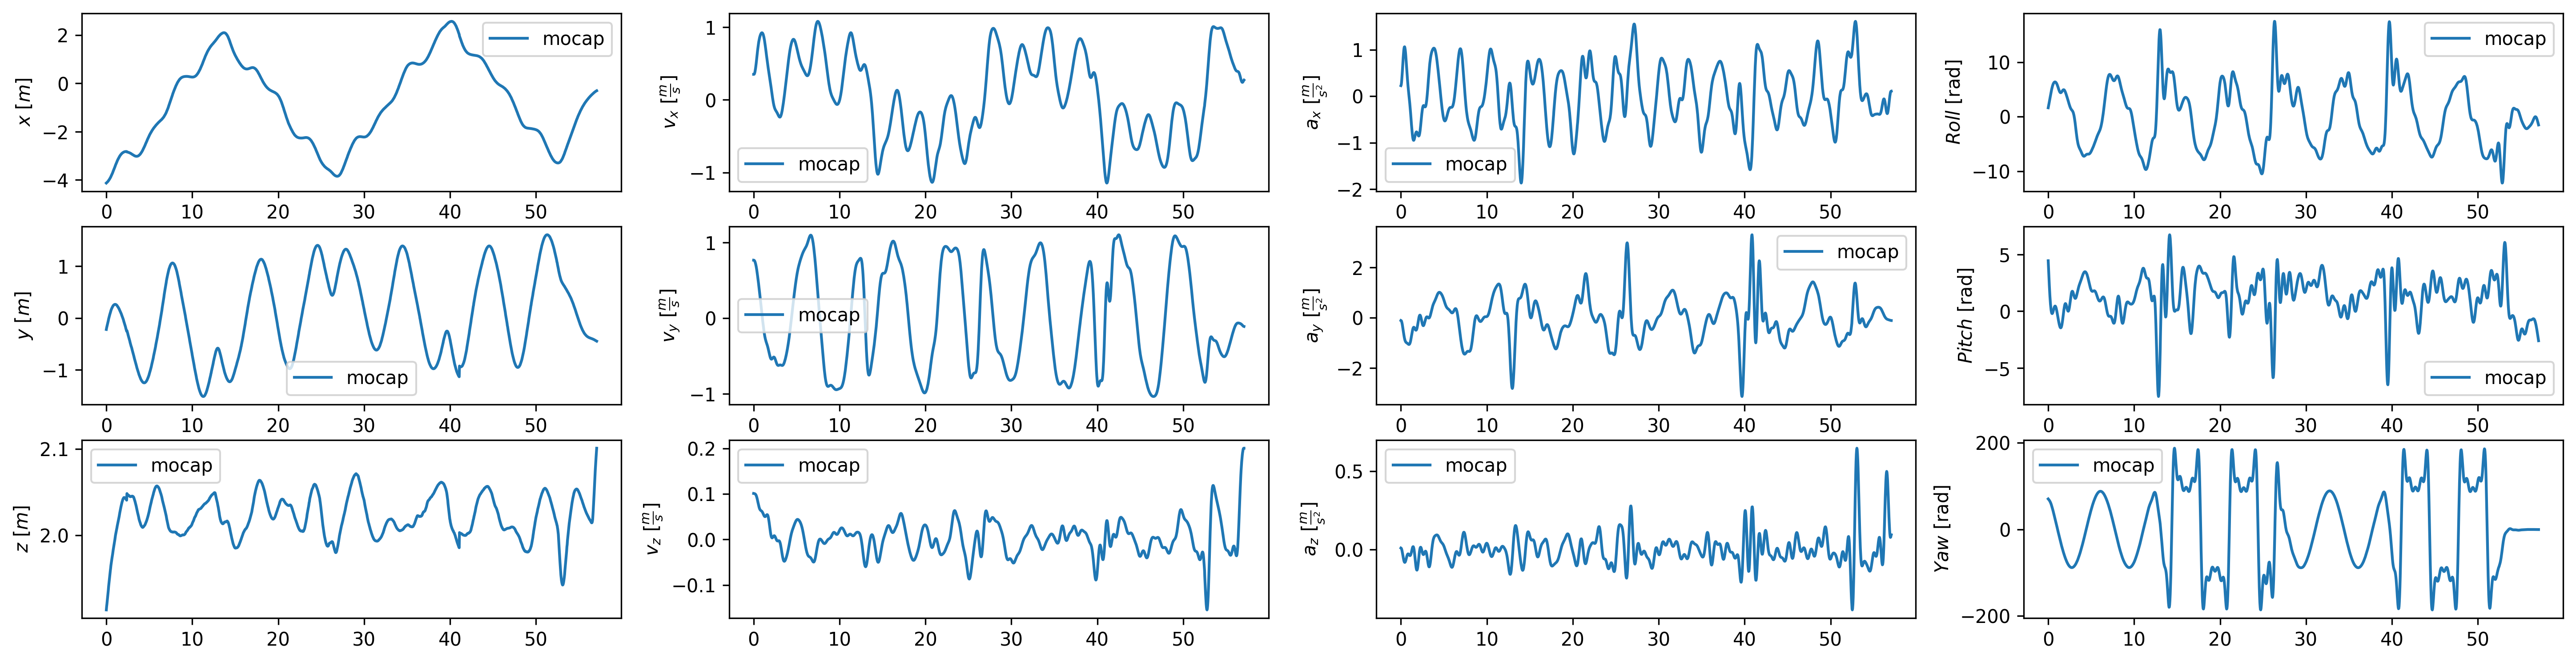

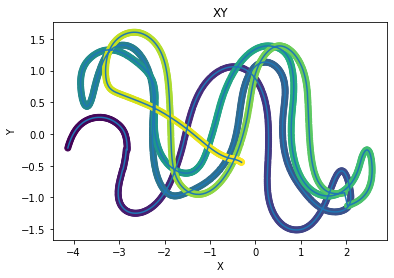

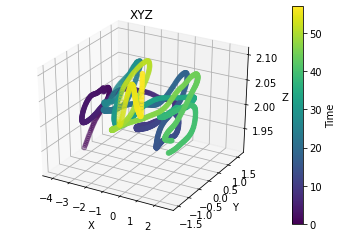

In [274]:
# plot the mocap data 
fig, ax = plt.subplots(3, 4, figsize=(3 * 8, 3 * 2), dpi=300)
# plot x
ax[0, 0].plot(mocap_time_shifted, mocap_X, label='mocap')
ax[0, 0].set_ylabel('$x$ [$m$]')
ax[0, 0].legend()
# plot y
ax[1, 0].plot(mocap_time_shifted, mocap_Y, label='mocap')
ax[1, 0].set_ylabel('$y$ [$m$]')
ax[1, 0].legend()
# plot z
ax[2, 0].plot(mocap_time_shifted, mocap_Z, label='mocap')
ax[2, 0].set_ylabel('$z$ [$m$]')
ax[2, 0].legend()
# plot x_dot
ax[0, 1].plot(mocap_time_shifted, mocap_X_dot, label='mocap')
ax[0, 1].set_ylabel(r'$v_x$ [$\frac{m}{s}$]')
ax[0, 1].legend()
# plot y_dot
ax[1, 1].plot(mocap_time_shifted, mocap_Y_dot, label='mocap')
ax[1, 1].set_ylabel(r'$v_y$ [$\frac{m}{s}$]')
ax[1, 1].legend()
# plot z_dot
ax[2, 1].plot(mocap_time_shifted, mocap_Z_dot, label='mocap')
ax[2, 1].set_ylabel(r'$v_z$ [$\frac{m}{s}$]')
ax[2, 1].legend()
# plot x_ddot
ax[0, 2].plot(mocap_time_shifted, mocap_X_ddot, label='mocap')
ax[0, 2].set_ylabel(r'$a_x$ [$\frac{m}{s^2}$]')
ax[0, 2].legend()
# plot y_ddot
ax[1, 2].plot(mocap_time_shifted, mocap_Y_ddot, label='mocap')
ax[1, 2].set_ylabel(r'$a_y$ [$\frac{m}{s^2}$]')
ax[1, 2].legend()
# plot z_ddot
ax[2, 2].plot(mocap_time_shifted, mocap_Z_ddot, label='mocap')
ax[2, 2].set_ylabel(r'$a_z$ [$\frac{m}{s^2}$]')
ax[2, 2].legend()
# plot Roll
ax[0, 3].plot(mocap_time_shifted, mocap_Roll, label='mocap')
ax[0, 3].set_ylabel('$Roll$ [rad]')
ax[0, 3].legend()
# plot Pitch
ax[1, 3].plot(mocap_time_shifted, mocap_Pitch, label='mocap')
ax[1, 3].set_ylabel('$Pitch$ [rad]')
ax[1, 3].legend()
# plot Yaw
ax[2, 3].plot(mocap_time_shifted, mocap_Yaw, label='mocap')
ax[2, 3].set_ylabel('$Yaw$ [rad]')
ax[2, 3].legend()
plt.show()

# x,y plot of the mocap data
plt.plot(mocap_X, mocap_Y)
plt.scatter(mocap_X, mocap_Y, label='start', c=mocap_time_shifted)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('XY')
plt.show()



# make 3d plot of XYZ with time as color
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(mocap_X, mocap_Y, mocap_Z, c=mocap_time_shifted)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title('XYZ')
plt.colorbar(sc, label='Time')
plt.show()

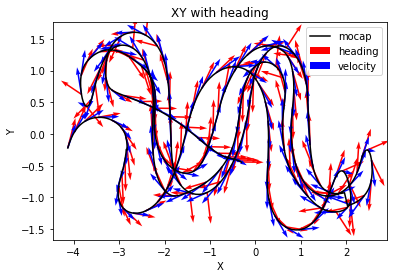

In [275]:
# plot X y data and add heading a s a quiver plot
fig, ax = plt.subplots()
ax.plot(mocap_X, mocap_Y,color='black', label='mocap')
# use mocap_yaw to get the heading
u = np.cos(np.radians(1*np.array(mocap_Yaw)))
v = np.sin(np.radians(1*np.array(mocap_Yaw)))
# plot every 10th point
ax.quiver(mocap_X[::10], mocap_Y[::10], u[::10], v[::10], angles='xy', scale_units='xy', scale=2, color='r', label='heading')
# add quiver based on velocity
Vu = mocap_X_dot
Vv = mocap_Y_dot
# plot every 10th point
ax.quiver(mocap_X[::10], mocap_Y[::10], Vu[::10], Vv[::10], angles='xy', scale_units='xy', scale=2, color='b', label='velocity')
ax.set_xlabel('X')
ax.set_ylabel('Y')
# add legend
ax.legend()
ax.set_title('XY with heading')
plt.show()

Text(0, 0.5, 'Y')

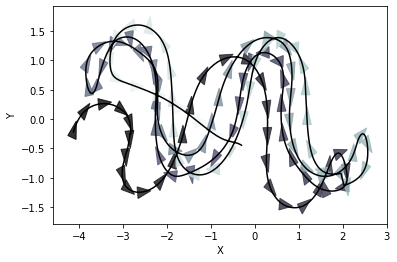

In [276]:
# make the heading arrows that point in the direction of yaw

# # overlay triangles with color by time
#         tri = np.array([[.1,0],[-.05,-.05],[-.05,.05]]) * scale
#         for i in range(0, len(tsim), marker_step):
#             R = np.array([[np.cos(psi[i]), -np.sin(psi[i])],
#                         [np.sin(psi[i]),  np.cos(psi[i])]])
#             tri_r = tri @ R.T
#             color = cmap(norm(tsim[i]))
#             plt.fill(x[i]+tri_r[:,0],
#                     y[i]+tri_r[:,1],
#                     color=color, alpha=0.8, edgecolor=None)


fig, ax = plt.subplots()
ax.plot(mocap_X, mocap_Y, color='black', label='mocap')
# use mocap_yaw to get the heading
tri = np.array([[.1, 0], [-.05, -0.05], [-.05, 0.05]]) * 2
marker_step = 15
cmap = plt.get_cmap('bone')
norm = mpl.colors.Normalize(vmin=mocap_time_shifted.min(), vmax=mocap_time_shifted.max())
for i in range(0, len(mocap_time_shifted), marker_step):
    R = np.array([[np.cos(np.radians(mocap_Yaw[i])), -np.sin(np.radians(mocap_Yaw[i]))],
                  [np.sin(np.radians(mocap_Yaw[i])),  np.cos(np.radians(mocap_Yaw[i]))]])
    tri_r = tri @ R.T
    color = cmap(norm(mocap_time_shifted[i]))
    ax.fill(mocap_X[i] + tri_r[:, 0], mocap_Y[i] + tri_r[:, 1], color=color, alpha=0.8, edgecolor=None)
# ax.scatter(mocap_X[::marker_step], mocap_Y[::marker_step], c=mocap_time_shifted[::marker_step], cmap='viridis', label='time')
ax.set_xlabel('X')
ax.set_ylabel('Y')
# ax.set_title('XY with heading arrows')

1.635069482043007 4.4386001117525735 70.28742100002219
velocity_body_dt: 29.999650786300368


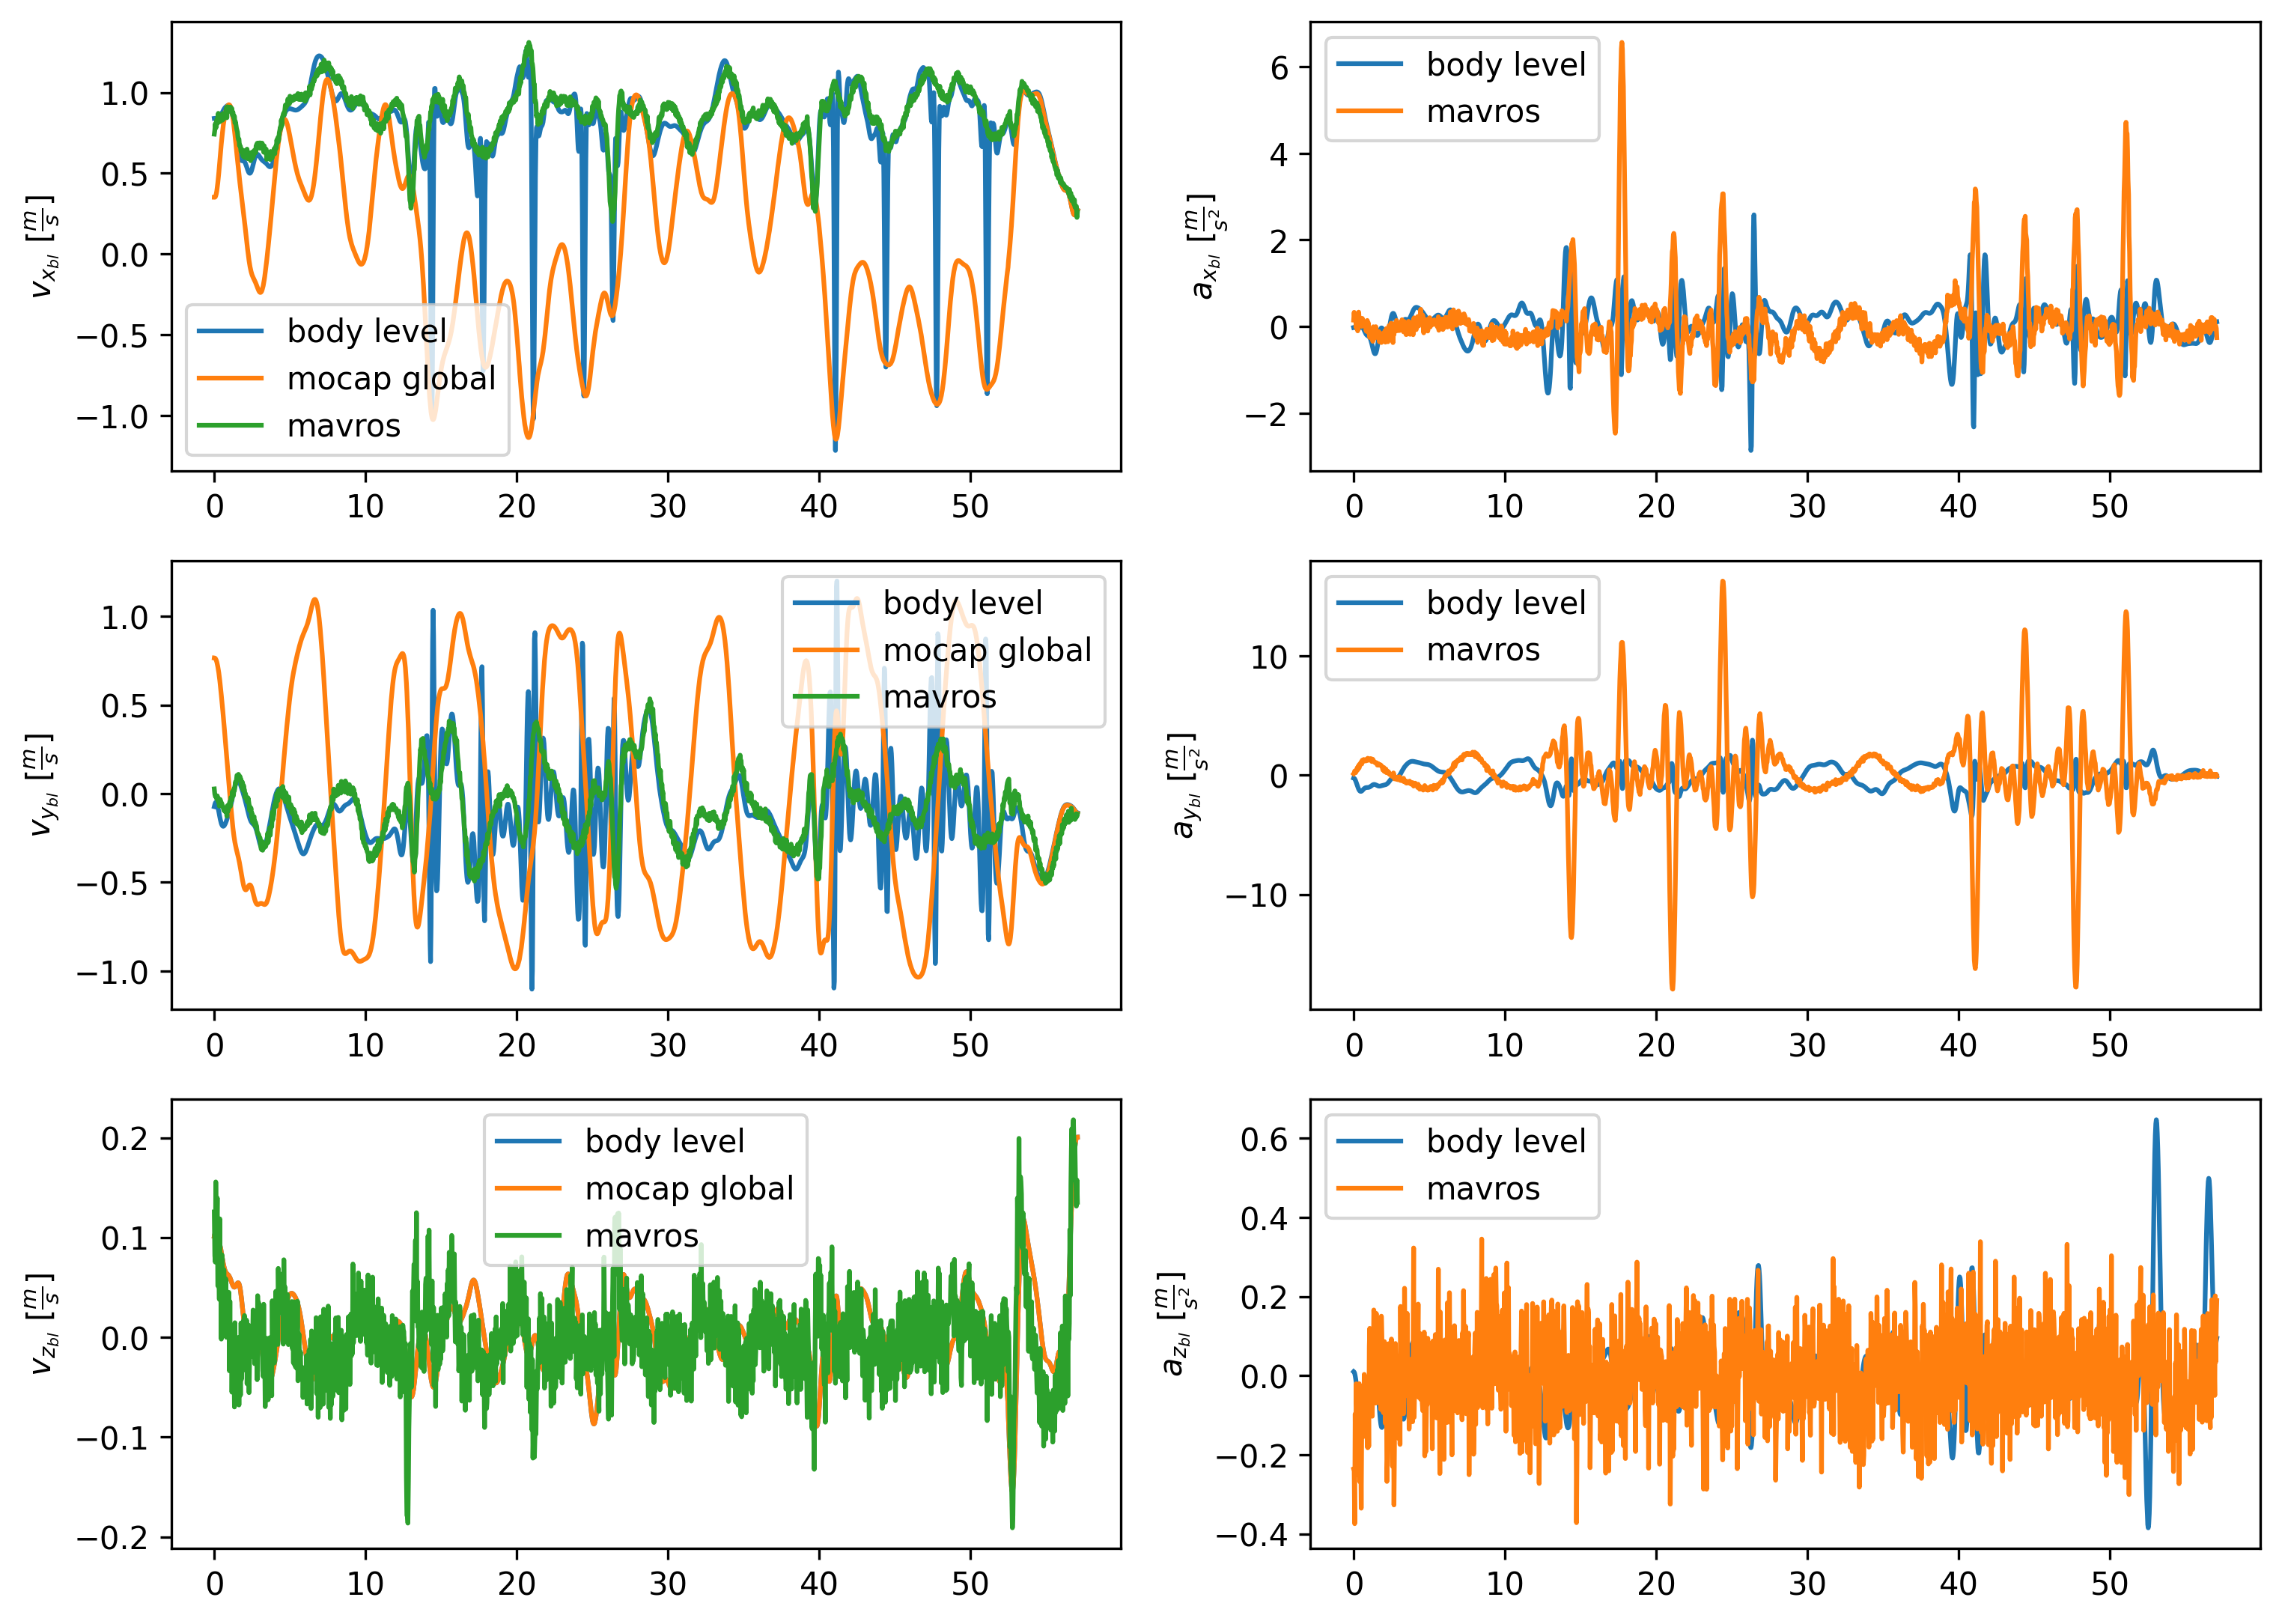

In [277]:
# R_G_BL (rotation from global to body level ) function that takes in roll, pitch, yaw and gives out the rotation matrix

def R_G_BL(roll, pitch, yaw):
    """
    Compute the rotation matrix from global frame to body-level frame.
    This only applies a yaw rotation (inverse of R_z) to align with the body-level frame.

    Args:
    roll  (float): Roll angle (phi) in radians.
    pitch (float): Pitch angle (theta) in radians.
    yaw   (float): Yaw angle (psi) in radians.

    Returns:
    numpy.ndarray: 3x3 rotation matrix from global to body-level frame.
    """
    R_z = np.array([[ np.cos(yaw), np.sin(yaw), 0],
                    [-np.sin(yaw), np.cos(yaw), 0],
                    [ 0, 0, 1]])

    return R_z  # This is R_z(-yaw), rotating global to body-level

    return R_G_BL
print(mocap_Roll[0], mocap_Pitch[0], mocap_Yaw[0])
# Rotate the velocity and acceleration from global to body level
mocap_bl_X_dot = []
mocap_bl_Y_dot = []
mocap_bl_Z_dot = []
mocap_bl_X_ddot = []
mocap_bl_Y_ddot = []
mocap_bl_Z_ddot = []

for i in range(len(mocap_Roll)):
    R_G_BL_i = R_G_BL(np.deg2rad(mocap_Roll[i]), np.deg2rad(mocap_Pitch[i]), np.deg2rad(mocap_Yaw[i]))
    
    # Velocity transformation
    velocity_vector = np.array([mocap_X_dot[i], mocap_Y_dot[i], mocap_Z_dot[i]])
    transformed_velocity = R_G_BL_i @ velocity_vector  # This returns a 3-element vector

    mocap_bl_X_dot.append(transformed_velocity[0])
    mocap_bl_Y_dot.append(transformed_velocity[1])
    mocap_bl_Z_dot.append(transformed_velocity[2])

    # Acceleration transformation
    acceleration_vector = np.array([mocap_X_ddot[i], mocap_Y_ddot[i], mocap_Z_ddot[i]])
    transformed_acceleration = R_G_BL_i @ acceleration_vector  # This returns a 3-element vector

    mocap_bl_X_ddot.append(transformed_acceleration[0])
    mocap_bl_Y_ddot.append(transformed_acceleration[1])
    mocap_bl_Z_ddot.append(transformed_acceleration[2])


data['mavros/local_position/velocity_body']
velocity_body_time = data['mavros/local_position/velocity_body']['rosbagTimestamp']/1e9/2
velocity_body_dt = np.mean(np.diff(velocity_body_time))
print('velocity_body_dt:', 1/velocity_body_dt)
# plt.plot(velocity_body_time, data['mavros/local_position/velocity_body']['x'], label='x')
velocity_body_x = data['mavros/local_position/velocity_body']['x']
velocity_body_y = data['mavros/local_position/velocity_body']['y']
velocity_body_z = data['mavros/local_position/velocity_body']['z']
velocity_body_x = interpolate_data(velocity_body_time, data['mavros/local_position/velocity_body']['x'], mocap_time)
velocity_body_y = interpolate_data(velocity_body_time, data['mavros/local_position/velocity_body']['y'], mocap_time)
velocity_body_z = interpolate_data(velocity_body_time, data['mavros/local_position/velocity_body']['z'], mocap_time)

smooth_params = [10, 0.025]
velocity_body_x_hat, accleration_body_x = pynumdiff.smooth_finite_difference.butterdiff(velocity_body_x, velocity_body_dt, smooth_params, options={'iterate': False})
velocity_body_y_hat, accleration_body_y = pynumdiff.smooth_finite_difference.butterdiff(velocity_body_y, velocity_body_dt, smooth_params, options={'iterate': False})
velocity_body_z_hat, accleration_body_z = pynumdiff.smooth_finite_difference.butterdiff(velocity_body_z, velocity_body_dt, smooth_params, options={'iterate': False})

acceleration_noise = 0.1

accleration_body_x = accleration_body_x + velocity_body_y_hat*np.deg2rad(mocap_Yaw_dot) + np.random.normal(0, acceleration_noise, len(accleration_body_x))
accleration_body_y = accleration_body_y - velocity_body_x_hat*np.deg2rad(mocap_Yaw_dot) + np.random.normal(0, acceleration_noise, len(accleration_body_y))
accleration_body_z = accleration_body_z + np.random.normal(0, acceleration_noise, len(accleration_body_z))

# plt.plot(velocity_body_time, vision_pose_velocity_x, label='mavros velocity x')
# plot the body level velocities and accelerations
fig, ax = plt.subplots(3, 2, figsize=(3 * 4, 3 * 3), dpi=300)
# plot x_dot
ax[0, 0].plot(mocap_time_shifted, mocap_bl_X_dot, label='body level')
ax[0, 0].plot(mocap_time_shifted, mocap_X_dot, label='mocap global')
ax[0, 0].plot(mocap_time_shifted, velocity_body_x, label='mavros')
ax[0, 0].set_ylabel(r'$v_{x_{bl}}$ [$\frac{m}{s}$]')
ax[0, 0].legend()
# plot y_dot
ax[1, 0].plot(mocap_time_shifted, mocap_bl_Y_dot, label='body level')
ax[1, 0].plot(mocap_time_shifted, mocap_Y_dot, label='mocap global')
ax[1, 0].plot(mocap_time_shifted, velocity_body_y, label='mavros')
ax[1, 0].set_ylabel(r'$v_{y_{bl}}$ [$\frac{m}{s}$]')
ax[1, 0].legend()
# plot z_dot
ax[2, 0].plot(mocap_time_shifted, mocap_bl_Z_dot, label='body level')
ax[2, 0].plot(mocap_time_shifted, mocap_Z_dot, label='mocap global')
ax[2, 0].plot(mocap_time_shifted, velocity_body_z, label='mavros')
ax[2, 0].set_ylabel(r'$v_{z_{bl}}$ [$\frac{m}{s}$]')
ax[2, 0].legend()
# plot x_ddot
ax[0, 1].plot(mocap_time_shifted, mocap_bl_X_ddot, label='body level')
# ax[0, 1].plot(mocap_time_shifted, mocap_X_ddot, label='mocap global')
ax[0, 1].plot(mocap_time_shifted, accleration_body_x, label='mavros')
ax[0, 1].set_ylabel(r'$a_{x_{bl}}$ [$\frac{m}{s^2}$]')
ax[0, 1].legend()
# plot y_ddot
ax[1, 1].plot(mocap_time_shifted, mocap_bl_Y_ddot, label='body level')
# ax[1, 1].plot(mocap_time_shifted, mocap_Y_ddot, label='mocap global')
ax[1, 1].plot(mocap_time_shifted, accleration_body_y, label='mavros')
ax[1, 1].set_ylabel(r'$a_{y_{bl}}$ [$\frac{m}{s^2}$]')
ax[1, 1].legend()
# plot z_ddot
ax[2, 1].plot(mocap_time_shifted, mocap_bl_Z_ddot, label='body level')
# ax[2, 1].plot(mocap_time_shifted, mocap_Z_ddot, label='mocap global')
ax[2, 1].plot(mocap_time_shifted, accleration_body_z, label='mavros')
ax[2, 1].set_ylabel(r'$a_{z_{bl}}$ [$\frac{m}{s^2}$]')
ax[2, 1].legend()
plt.show()


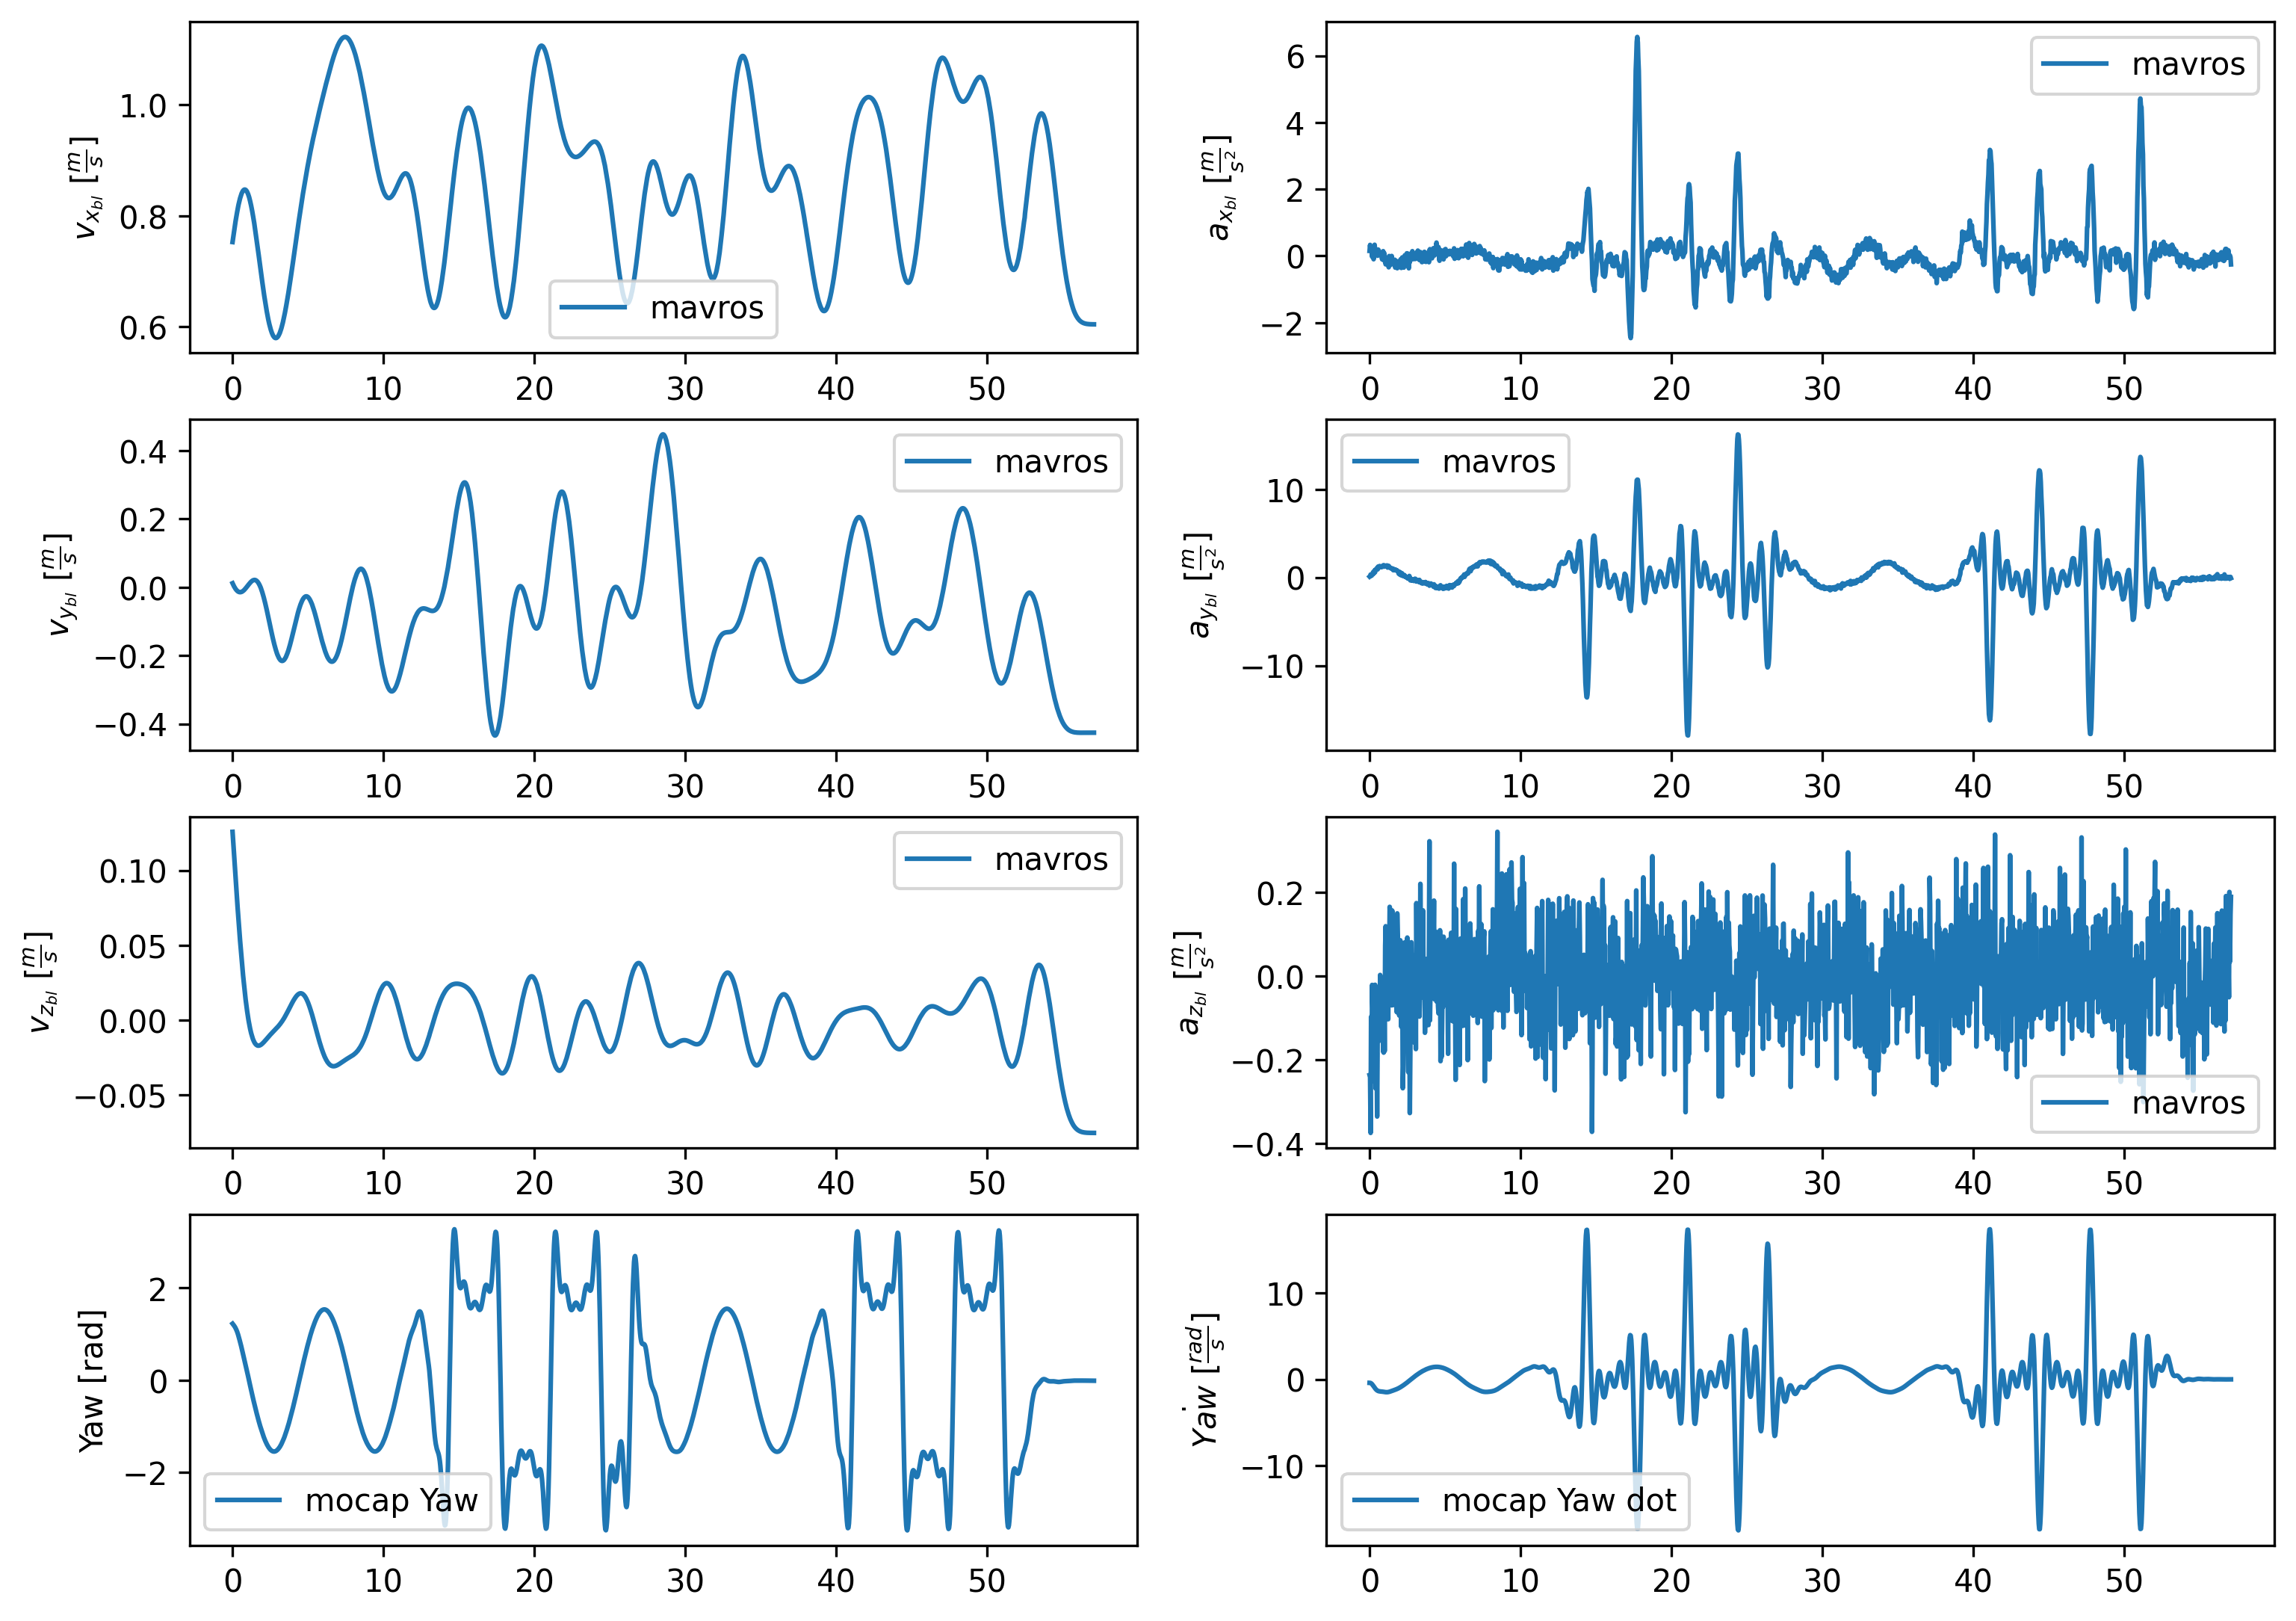

In [278]:
fig, ax = plt.subplots(4, 2, figsize=(3 * 4, 3 * 3), dpi=300)
# plot x_dot

ax[0, 0].plot(mocap_time_shifted, velocity_body_x_hat, label='mavros')
ax[0, 0].set_ylabel(r'$v_{x_{bl}}$ [$\frac{m}{s}$]')
ax[0, 0].legend()
# plot y_dot
ax[1, 0].plot(mocap_time_shifted, velocity_body_y_hat, label='mavros')
ax[1, 0].set_ylabel(r'$v_{y_{bl}}$ [$\frac{m}{s}$]')
ax[1, 0].legend()
# plot z_dot
ax[2, 0].plot(mocap_time_shifted, velocity_body_z_hat, label='mavros')
ax[2, 0].set_ylabel(r'$v_{z_{bl}}$ [$\frac{m}{s}$]')
ax[2, 0].legend()
# plot x_ddot
# ax[0, 1].plot(mocap_time_shifted, mocap_bl_X_ddot, label='body level')
# ax[0, 1].plot(mocap_time_shifted, mocap_X_ddot, label='mocap global')
ax[0, 1].plot(mocap_time_shifted, accleration_body_x, label='mavros')
ax[0, 1].set_ylabel(r'$a_{x_{bl}}$ [$\frac{m}{s^2}$]')
ax[0, 1].legend()
# plot y_ddot
# ax[1, 1].plot(mocap_time_shifted, mocap_bl_Y_ddot, label='body level')
# ax[1, 1].plot(mocap_time_shifted, mocap_Y_ddot, label='mocap global')
ax[1, 1].plot(mocap_time_shifted, accleration_body_y, label='mavros')
ax[1, 1].set_ylabel(r'$a_{y_{bl}}$ [$\frac{m}{s^2}$]')
ax[1, 1].legend()
# plot z_ddot
# ax[2, 1].plot(mocap_time_shifted, mocap_bl_Z_ddot, label='body level')
# ax[2, 1].plot(mocap_time_shifted, mocap_Z_ddot, label='mocap global')
ax[2, 1].plot(mocap_time_shifted, accleration_body_z, label='mavros')
ax[2, 1].set_ylabel(r'$a_{z_{bl}}$ [$\frac{m}{s^2}$]')
ax[2, 1].legend()
ax[3, 0].plot(mocap_time_shifted,np.deg2rad(mocap_Yaw_hat), label='mocap Yaw')
ax[3, 0].set_ylabel(r'Yaw [rad]')
ax[3, 0].legend()
ax[3, 1].plot(mocap_time_shifted, np.deg2rad(mocap_Yaw_dot), label='mocap Yaw dot')
ax[3, 1].set_ylabel(r'$\dot{Yaw}$ [$\frac{rad}{s}$]')
ax[3, 1].legend()
plt.show()

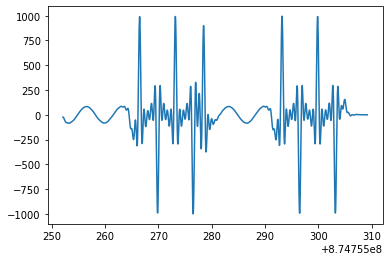

In [279]:
plt.plot(mocap_time,mocap_Yaw_dot)

velocity_body_dt: 29.999650786300368


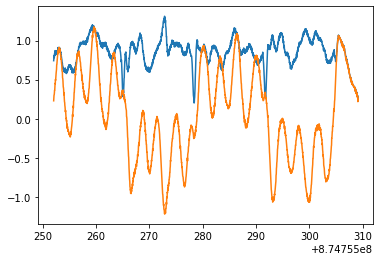

In [280]:
data['mavros/local_position/velocity_body']
velocity_body_time = data['mavros/local_position/velocity_body']['rosbagTimestamp']/1e9/2
velocity_body_dt = np.mean(np.diff(velocity_body_time))
print('velocity_body_dt:', 1/velocity_body_dt)
plt.plot(velocity_body_time, data['mavros/local_position/velocity_body']['x'], label='x')
plt.plot(velocity_body_time, data['mavros/local_position/velocity_local']['x'], label='x')

# IMU [Roll($\phi$),Pitch($\theta$),Yaw($\psi$)] + [$\omega_x$,$\omega_y$,$\omega_z$] + [$A_x$,$A_y$,$A_z$]

imu dt: 49.999083016175625
mocap dt: 29.99964934495999


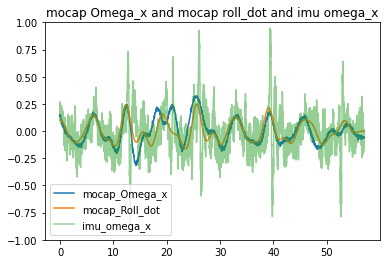

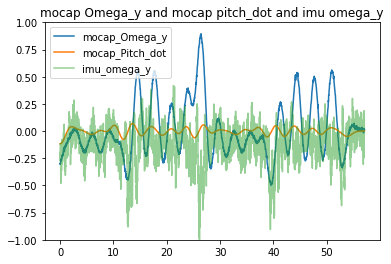

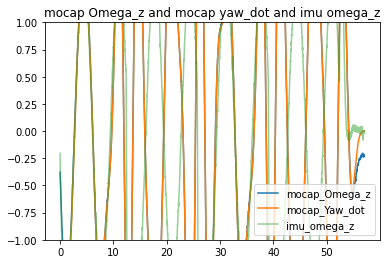

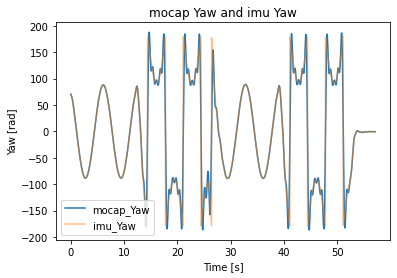

In [281]:
imu_time = data['mavros/imu/data']['rosbagTimestamp']/1e9/2
imu_time_shifted = imu_time - imu_time[0]
imu_Roll, imu_Pitch, imu_Yaw = [], [], []
for i in range(len(data['mavros/imu/data'])):
    R, P, Y = quaternion_to_euler(data['mavros/imu/data']['x'][i],
                                  data['mavros/imu/data']['y'][i],
                                  data['mavros/imu/data']['z'][i],
                                  data['mavros/imu/data']['w'][i])
    imu_Roll.append(np.radians(R))
    imu_Pitch.append(np.radians(P))
    imu_Yaw.append(np.radians(Y))

imu_omega_x = data['mavros/imu/data']['x.1']
imu_omega_y = data['mavros/imu/data']['y.1']
imu_omega_z = data['mavros/imu/data']['z.1']

# function that goes from omega_dot to phi_dot, theta_dot, psi_dot

def omega_to_euler_dot(omega_x, omega_y, omega_z, phi, theta, psi):
    """
    Converts angular velocity components (omega_x, omega_y, omega_z)
    to Euler angle rates (phi_dot, theta_dot, psi_dot).

    input: omega_x, omega_y, omega_z, phi, theta
    output: phi_dot, theta_dot, psi_dot
    """
    phi_dot = omega_x + omega_y * np.tan(theta) * np.sin(phi) + omega_z * np.tan(theta) * np.cos(phi)
    theta_dot = omega_y * np.cos(phi) - omega_z * np.sin(phi)
    psi_dot = omega_y * np.sin(phi) / np.cos(theta) + omega_z * np.cos(phi) / np.cos(theta)

    return phi_dot, theta_dot, psi_dot

def euler_dot_to_omega(phi_dot, theta_dot, psi_dot, phi, theta, psi):
    """
    Converts Euler angle rates (phi_dot, theta_dot, psi_dot)
    to angular velocity components (omega_x, omega_y, omega_z).

    input: phi_dot, theta_dot, psi_dot, phi, theta
    output: omega_x, omega_y, omega_z
    """
    omega_x = phi_dot - psi_dot * np.sin(theta)
    omega_y = theta_dot * np.cos(phi) + psi_dot * np.cos(theta) * np.sin(phi)
    omega_z = -theta_dot * np.sin(phi) + psi_dot * np.cos(theta) * np.cos(phi)

    return omega_x, omega_y, omega_z

imu_phi_dot, imu_theta_dot, imu_psi_dot = [], [], []
for i in range(len(data['mavros/imu/data'])):
    phi_dot, theta_dot, psi_dot = omega_to_euler_dot(imu_omega_x[i],
                                                         imu_omega_y[i],
                                                         imu_omega_z[i],
                                                         imu_Roll[i],
                                                         imu_Pitch[i],
                                                         imu_Yaw[i])
    imu_phi_dot.append(phi_dot)
    imu_theta_dot.append(theta_dot)
    imu_psi_dot.append(psi_dot)
# using mocap data get Omega_x, Omega_y, Omega_z
mocap_Omega_x, mocap_Omega_y, mocap_Omega_z = [], [], []
for i in range(len(data['mavros/local_position/pose'])):
    omega_x, omega_y, omega_z = euler_dot_to_omega(np.gradient(np.deg2rad(mocap_Roll), mocap_time)[i],
                                                    np.gradient(np.deg2rad(mocap_Pitch), mocap_time)[i],
                                                    np.gradient(np.deg2rad(mocap_Yaw), mocap_time)[i],
                                                    np.deg2rad(mocap_Roll[i]),
                                                    np.deg2rad(mocap_Pitch[i]),
                                                    np.deg2rad(mocap_Yaw[i]))
    mocap_Omega_x.append(omega_x)
    mocap_Omega_y.append(omega_y)
    mocap_Omega_z.append(omega_z)

# use pynumdif to smooth the mocap Omega data
# smooth_params = [10, 0.09]
mocap_Omega_x, mocap_Omega_x_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Omega_x, mocap_dt, smooth_params, options={'iterate': False})
mocap_Omega_y, mocap_Omega_y_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Omega_y, mocap_dt, smooth_params, options={'iterate': False})
mocap_Omega_z, mocap_Omega_z_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Omega_z, mocap_dt, smooth_params, options={'iterate': False})
mocap_omega_noise = 0.01
mocap_Omega_x = mocap_Omega_x + np.random.normal(0, mocap_omega_noise, len(mocap_Omega_x))
mocap_Omega_y = mocap_Omega_y + np.random.normal(0, mocap_omega_noise, len(mocap_Omega_y))
mocap_Omega_z = mocap_Omega_z + np.random.normal(0, mocap_omega_noise, len(mocap_Omega_z))


# mocap_Omega_x = remove_outliers(mocap_Omega_x, method='iqr', threshold=1.5)
# mocap_Omega_y = remove_outliers(mocap_Omega_y, method='iqr', threshold=1.5)
# mocap_Omega_z = remove_outliers(mocap_Omega_z, method='iqr', threshold=1.5)                                                   

# function that goes from phi_dot, theta_dot, psi_dot to omega_x, omega_y, omega_z
def euler_dot_to_omega_dot(phi_dot, theta_dot, psi_dot, phi, theta):
    """
    input: phi_dot, theta_dot, psi_dot, phi, theta
    output: omega_x, omega_y, omega_z
    """
    omega_x = phi_dot - psi_dot * np.sin(theta)
    omega_y = theta_dot * np.cos(phi) + psi_dot * np.cos(theta) * np.sin(phi)
    omega_z = psi_dot * np.cos(theta) * np.cos(phi) - theta_dot * np.sin(phi)
    return omega_x, omega_y, omega_z

# take the gradient of imu_roll, imu_pitch, imu_yaw to get the angular velocities
# imu_Roll_dot = np.gradient(imu_Roll, imu_time)
# imu_Pitch_dot = np.gradient(imu_Pitch, imu_time)
# imu_Yaw_dot = np.gradient(imu_Yaw, imu_time)

# smooth_params = [10, 0.09]
imu_Roll_hat, imu_Roll_dot = pynumdiff.smooth_finite_difference.butterdiff(imu_Roll, np.mean(np.diff(imu_time)), smooth_params, options={'iterate': False})
imu_Pitch_hat, imu_Pitch_dot = pynumdiff.smooth_finite_difference.butterdiff(imu_Pitch, np.mean(np.diff(imu_time)), smooth_params, options={'iterate': False})
imu_Yaw_hat, imu_Yaw_dot = pynumdiff.smooth_finite_difference.butterdiff(imu_Yaw, np.mean(np.diff(imu_time)), smooth_params, options={'iterate': False})


# smooth_params = [10, 0.09]
mocap_Roll_hat, mocap_Roll_dot = pynumdiff.smooth_finite_difference.butterdiff(np.deg2rad(mocap_Roll), mocap_dt, smooth_params, options={'iterate': False})
mocap_Pitch_hat, mocap_Pitch_dot = pynumdiff.smooth_finite_difference.butterdiff(np.deg2rad(mocap_Pitch), mocap_dt, smooth_params, options={'iterate': False})
mocap_Yaw_hat, mocap_Yaw_dot = pynumdiff.smooth_finite_difference.butterdiff(np.deg2rad(mocap_Yaw), mocap_dt, smooth_params, options={'iterate': False})

# mocap_Roll_dot=remove_outliers(np.gradient(np.deg2rad(mocap_Roll), mocap_time), method='iqr', threshold=1.5)
# mocap_Pitch_dot=remove_outliers(np.gradient(np.deg2rad(mocap_Pitch), mocap_time), method='iqr', threshold=1.5)
# mocap_Yaw_dot=remove_outliers(np.gradient(np.deg2rad(mocap_Yaw), mocap_time), method='iqr', threshold=1.5)

print('imu dt:', 1/np.mean(np.diff(imu_time)))
print('mocap dt:', 1/np.mean(np.diff(mocap_time)))
# interpolate IMU to mocap time
# imu_omega_x = interpolate_data(imu_time, imu_omega_x, mocap_time)
# imu_omega_y = interpolate_data(imu_time, imu_omega_y, mocap_time)
# imu_omega_z = interpolate_data(imu_time, imu_omega_z, mocap_time)


plt.plot(mocap_time_shifted, mocap_Omega_x, label='mocap_Omega_x')
plt.plot(mocap_time_shifted, mocap_Roll_dot, label='mocap_Roll_dot')
plt.plot(imu_time_shifted, imu_omega_x, label='imu_omega_x',alpha=.5)
plt.title('mocap Omega_x and mocap roll_dot and imu omega_x')
plt.ylim(-1,1)
plt.legend()
plt.show()


plt.plot(mocap_time_shifted, mocap_Omega_y, label='mocap_Omega_y')
plt.plot(mocap_time_shifted, mocap_Pitch_dot, label='mocap_Pitch_dot')
plt.plot(imu_time_shifted, imu_omega_y, label='imu_omega_y',alpha=.5)
plt.title('mocap Omega_y and mocap pitch_dot and imu omega_y')
plt.ylim(-1,1)
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, mocap_Omega_z, label='mocap_Omega_z')
plt.plot(mocap_time_shifted, mocap_Yaw_dot, label='mocap_Yaw_dot')
plt.plot(imu_time_shifted, imu_omega_z, label='imu_omega_z',alpha=.5)
plt.title('mocap Omega_z and mocap yaw_dot and imu omega_z')
plt.ylim(-1,1)
plt.legend()
plt.show()

# plot mocap yae and imu yaw
plt.plot(mocap_time_shifted, mocap_Yaw, label='mocap_Yaw')
plt.plot(imu_time_shifted, np.rad2deg(imu_Yaw), label='imu_Yaw',alpha=.5)
plt.title('mocap Yaw and imu Yaw')
plt.xlabel('Time [s]')
plt.ylabel('Yaw [rad]')
plt.legend()
plt.show()

In [282]:
data['mavros/local_position/pose']

,rosbagTimestamp,header,seq,stamp,secs,nsecs,frame_id,pose,position,x,y,z,orientation,x.1,y.1,z.1,w
0,1749510504186566391,NaN,85025,NaN,1748040119,93810688,"""map""",NaN,NaN,-4.128503,-0.220388,1.913257,NaN,0.010541,-0.040133,-0.575489,-0.816756
1,1749510504254510253,NaN,85026,NaN,1748040119,135810688,"""map""",NaN,NaN,-4.115859,-0.189741,1.917064,NaN,0.007845,-0.038860,-0.573557,-0.818206
2,1749510504322080610,NaN,85027,NaN,1748040119,167813760,"""map""",NaN,NaN,-4.105484,-0.166413,1.919884,NaN,0.000636,-0.036567,-0.567896,-0.822287
3,1749510504384390738,NaN,85028,NaN,1748040119,199813760,"""map""",NaN,NaN,-4.094476,-0.142901,1.923003,NaN,-0.005757,-0.034049,-0.561126,-0.827010
4,1749510504452291057,NaN,85029,NaN,1748040119,231813760,"""map""",NaN,NaN,-4.082700,-0.119411,1.926232,NaN,-0.009398,-0.032264,-0.556500,-0.830168
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1708,1749510618054739092,NaN,86733,NaN,1748040176,34697152,"""map""",NaN,NaN,-0.334163,-0.433465,2.080544,NaN,-0.006454,-0.017172,-0.005352,0.999817
1709,1749510618117019573,NaN,86734,NaN,1748040176,65699712,"""map""",NaN,NaN,-0.326420,-0.436658,2.085806,NaN,-0.008443,-0.018791,-0.005514,0.999773
1710,1749510618185271830,NaN,86735,NaN,1748040176,98699712,"""map""",NaN,NaN,-0.319107,-0.439807,2.090954,NaN,-0.010096,-0.020372,-0.005720,0.999725
1711,1749510618257557776,NaN,86736,NaN,1748040176,129699712,"""map""",NaN,NaN,-0.312202,-0.442929,2.095948,NaN,-0.011861,-0.020289,-0.005834,0.999707


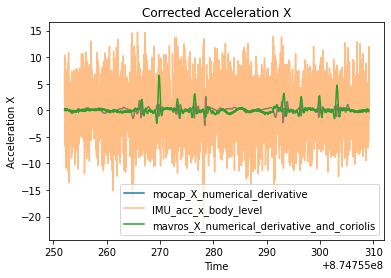

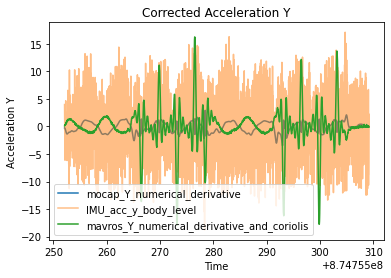

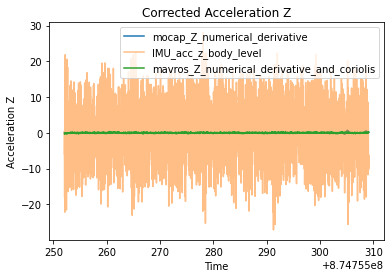

In [283]:
g = 9.81  # Gravitational acceleration (m/s^2)

# Function to compute the rotation matrix from roll, pitch, yaw
def rotation_matrix_from_euler(roll, pitch, yaw):
    """
    Creates a rotation matrix from roll, pitch, yaw angles (in radians).
    """
    # Compute rotation matrices for roll, pitch, and yaw
    R_roll = np.array([
        [1, 0, 0],
        [0, np.cos(roll), -np.sin(roll)],
        [0, np.sin(roll), np.cos(roll)]
    ])
    
    R_pitch = np.array([
        [np.cos(pitch), 0, np.sin(pitch)],
        [0, 1, 0],
        [-np.sin(pitch), 0, np.cos(pitch)]
    ])
    
    R_yaw = np.array([
        [np.cos(yaw), -np.sin(yaw), 0],
        [np.sin(yaw), np.cos(yaw), 0],
        [0, 0, 1]
    ])
    
    # Combine the rotation matrices (Z * Y * X)
    R = R_yaw @ R_pitch @ R_roll
    return R

# Function to remove gravity from linear acceleration
def remove_gravity_from_acceleration(acc_x, acc_y, acc_z, roll, pitch, yaw):
    """
    Removes the gravity component from the linear acceleration in the body frame.
    
    acc_x, acc_y, acc_z: numpy arrays
        Arrays of linear acceleration in the body frame along the x, y, and z axes.
    roll, pitch, yaw: numpy arrays
        Arrays of roll, pitch, and yaw angles (in radians).
    
    Returns:
    acc_x_corrected, acc_y_corrected, acc_z_corrected: numpy arrays
        Corrected linear accelerations with gravity removed along the x, y, and z axes.
    """
    # Initialize corrected acceleration arrays
    acc_x_corrected = np.zeros_like(acc_x)
    acc_y_corrected = np.zeros_like(acc_y)
    acc_z_corrected = np.zeros_like(acc_z)
    
    # Gravity vector in the world frame (assume gravity points along the Z-axis)
    gravity_world = np.array([0, 0, g])
    
    # Loop over each time step and correct the acceleration
    for i in range(len(acc_x)):
        # Get the rotation matrix for the current orientation (roll, pitch, yaw)
        R = rotation_matrix_from_euler(roll[i], pitch[i], yaw[i])
        
        # Transform gravity vector from world frame to body frame
        gravity_body = R.T @ gravity_world  # Transpose R to rotate from world to body
        
        # Measured acceleration in body frame
        acc_body = np.array([acc_x[i], acc_y[i], acc_z[i]])
        
        # Subtract gravity from the body-frame acceleration
        acc_corrected = acc_body - gravity_body
        
        # Store the corrected acceleration
        acc_x_corrected[i] = acc_corrected[0]
        acc_y_corrected[i] = acc_corrected[1]
        acc_z_corrected[i] = acc_corrected[2]
    
    return acc_x_corrected, acc_y_corrected, acc_z_corrected

# Remove gravity from the linear acceleration
imu_acc_x_corrected, imu_acc_y_corrected, imu_acc_z_corrected = remove_gravity_from_acceleration(
    data['mavros/imu/data']['x.2'],
    data['mavros/imu/data']['y.2'],
    data['mavros/imu/data']['z.2'],
    imu_Roll, imu_Pitch, imu_Yaw
)

# rotate the acceleration data to the world frame
def rotate_acceleration_to_world_frame(acc_x, acc_y, acc_z, roll, pitch, yaw):
    """
    Rotates the linear acceleration from the body frame to the world frame.
    
    acc_x, acc_y, acc_z: numpy arrays
        Arrays of linear acceleration in the body frame along the x, y, and z axes.
    roll, pitch, yaw: numpy arrays
        Arrays of roll, pitch, and yaw angles (in radians).
    
    Returns:
    acc_x_world, acc_y_world, acc_z_world: numpy arrays
        Linear acceleration in the world frame along the x, y, and z axes.
    """
    # Initialize world-frame acceleration arrays
    acc_x_world = np.zeros_like(acc_x)
    acc_y_world = np.zeros_like(acc_y)
    acc_z_world = np.zeros_like(acc_z)
    
    # Loop over each time step and rotate the acceleration
    for i in range(len(acc_x)):
        # Get the rotation matrix for the current orientation (roll, pitch, yaw)
        R = rotation_matrix_from_euler(roll[i], pitch[i], yaw[i])
        
        # Measured acceleration in body frame
        acc_body = np.array([acc_x[i], acc_y[i], acc_z[i]])
        
        # Rotate the body-frame acceleration to the world frame
        acc_world = R @ acc_body
        
        # Store the world-frame acceleration
        acc_x_world[i] = acc_world[0]
        acc_y_world[i] = acc_world[1]
        acc_z_world[i] = acc_world[2]
    
    return acc_x_world, acc_y_world, acc_z_world

# Rotate the acceleration data to the world frame
imu_acc_x_corrected_world, imu_acc_y_corrected_world, imu_acc_z_corrected_world = rotate_acceleration_to_world_frame(
    imu_acc_x_corrected, imu_acc_y_corrected, imu_acc_z_corrected, imu_Roll, imu_Pitch, imu_Yaw
)


# creat rotation from body to body level frame ie roll and pitch
def rotation_matrix_from_roll_pitch(roll, pitch):
    """
    Creates a rotation matrix from roll and pitch angles (in radians).
    """
    # Compute rotation matrices for roll and pitch
    R_roll = np.array([
        [1, 0, 0],
        [0, np.cos(roll), -np.sin(roll)],
        [0, np.sin(roll), np.cos(roll)]
    ])
    
    R_pitch = np.array([
        [np.cos(pitch), 0, np.sin(pitch)],
        [0, 1, 0],
        [-np.sin(pitch), 0, np.cos(pitch)]
    ])
    
    # Combine the rotation matrices
    R_b_bl = R_pitch @ R_roll
    return R_b_bl

# rotate the acceleration from the body frame to the body level frame
def rotate_acceleration_to_body_level_frame(acc_x, acc_y, acc_z, roll, pitch):
    """
    Rotates the linear acceleration from the body frame to the body level frame.
    
    acc_x, acc_y, acc_z: numpy arrays
        Arrays of linear acceleration in the body frame along the x, y, and z axes.
    roll, pitch: numpy arrays
        Arrays of roll and pitch angles (in radians).
    
    Returns:
    acc_x_body_level, acc_y_body_level, acc_z_body_level: numpy arrays
        Linear acceleration in the body level frame along the x, y, and z axes.
    """
    # Initialize body-level acceleration arrays
    acc_x_body_level = np.zeros_like(acc_x)
    acc_y_body_level = np.zeros_like(acc_y)
    acc_z_body_level = np.zeros_like(acc_z)
    
    # Loop over each time step and rotate the acceleration
    for i in range(len(acc_x)):
        # Get the rotation matrix for the current orientation (roll, pitch)
        R = rotation_matrix_from_roll_pitch(roll[i], pitch[i])
        
        # Measured acceleration in body frame
        acc_body = np.array([acc_x[i], acc_y[i], acc_z[i]])
        
        # Rotate the body-frame acceleration to the body level frame
        acc_body_level = R @ acc_body
        
        # Store the body-level acceleration
        acc_x_body_level[i] = acc_body_level[0]
        acc_y_body_level[i] = acc_body_level[1]
        acc_z_body_level[i] = acc_body_level[2]
    
    return acc_x_body_level, acc_y_body_level, acc_z_body_level

acc_x_body_level, acc_y_body_level, acc_z_body_level = rotate_acceleration_to_body_level_frame(
    imu_acc_x_corrected, imu_acc_y_corrected, imu_acc_z_corrected, imu_Roll, imu_Pitch
)
# def low_pass_filter(data, dt, cut_off_freq):
# acc_x_body_level=low_pass_filter(acc_x_body_level, np.mean(np.diff(imu_time)), 5)

# create acceleration from velocity bl
mavros_bl_Velocity_x = data['mavros/local_position/velocity_body']['x']
mavros_bl_Velocity_y = data['mavros/local_position/velocity_body']['y']
mavros_bl_Velocity_z = data['mavros/local_position/velocity_body']['z']



# plt.plot(imu_time, imu_acc_x_corrected_world,label='imu_acc_x_corrected')
plt.plot(mocap_time, mocap_bl_X_ddot,label='mocap_X_numerical_derivative')
plt.plot(imu_time, acc_x_body_level,label='IMU_acc_x_body_level',alpha=0.5)
plt.plot(mocap_time, accleration_body_x, label='mavros_X_numerical_derivative_and_coriolis')
# plt.plot(mocap_time, mocap_X_ddot,label='mocap_X_ddot',alpha=0.5)
plt.title('Corrected Acceleration X')
plt.xlabel('Time')
plt.ylabel('Acceleration X')
plt.legend()
plt.show()

# plt.plot(imu_time, imu_acc_y_corrected_world,label='imu_acc_y_corrected')
plt.plot(mocap_time, mocap_bl_Y_ddot,label='mocap_Y_numerical_derivative')
plt.plot(imu_time, acc_y_body_level,label='IMU_acc_y_body_level',alpha=0.5)
plt.plot(mocap_time, accleration_body_y, label='mavros_Y_numerical_derivative_and_coriolis')
# plt.plot(mocap_time, mocap_Y_ddot,label='mocap_Y_ddot',alpha=0.5)
plt.title('Corrected Acceleration Y')
plt.xlabel('Time')
plt.ylabel('Acceleration Y')
plt.legend()
plt.show()

# plt.plot(imu_time, imu_acc_z_corrected_world,label='imu_acc_z_corrected')
plt.plot(mocap_time, mocap_bl_Z_ddot,label='mocap_Z_numerical_derivative')
plt.plot(imu_time, acc_z_body_level,label='IMU_acc_z_body_level',alpha=0.5)
plt.plot(mocap_time, accleration_body_z, label='mavros_Z_numerical_derivative_and_coriolis')
# plt.plot(mocap_time, mocap_Z_ddot,label='mocap_Z_ddot',alpha=0.5)
plt.title('Corrected Acceleration Z')
plt.xlabel('Time')
plt.ylabel('Acceleration Z')
plt.legend()
plt.show()


# optic flow (body level) - camera data

optic_flow_camera_dt: 29.97697102700032


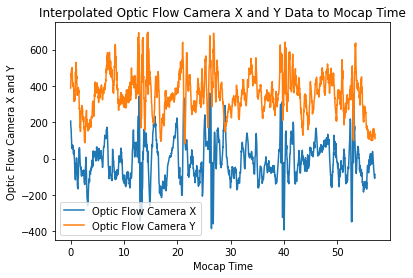

In [284]:
optic_flow_camera_x_time = data['optic_flow/camera/mean/x']['rosbagTimestamp']/1e9/2
optic_flow_camera_y_time = data['optic_flow/camera/mean/y']['rosbagTimestamp']/1e9/2
optic_flow_camera_x = data['optic_flow/camera/mean/x']['data']
optic_flow_camera_y = data['optic_flow/camera/mean/y']['data']

# get dt of optic flow camera data
optic_flow_camera_dt = np.mean(np.diff(optic_flow_camera_x_time))
print('optic_flow_camera_dt:', 1/optic_flow_camera_dt)

# interpolate optic flow camera data to mocap time
optic_flow_camera_x_mocap_interp = interpolate_data(optic_flow_camera_x_time, optic_flow_camera_x, mocap_time)
optic_flow_camera_y_mocap_interp = interpolate_data(optic_flow_camera_y_time, optic_flow_camera_y, mocap_time)

optic_flow_camera_x_mocap_interp=optic_flow_camera_x_mocap_interp
optic_flow_camera_y_mocap_interp=optic_flow_camera_y_mocap_interp

optic_flow_camera_x_mocap_interp[np.abs(optic_flow_camera_x_mocap_interp - np.median(optic_flow_camera_x_mocap_interp)) > 3 * np.std(optic_flow_camera_x_mocap_interp)] = np.median(optic_flow_camera_x_mocap_interp)
optic_flow_camera_y_mocap_interp[np.abs(optic_flow_camera_y_mocap_interp - np.median(optic_flow_camera_y_mocap_interp)) > 3 * np.std(optic_flow_camera_y_mocap_interp)] = np.median(optic_flow_camera_y_mocap_interp)

# Plot the interpolated data
plt.plot(mocap_time_shifted, optic_flow_camera_x_mocap_interp, label="Optic Flow Camera X")
plt.plot(mocap_time_shifted, optic_flow_camera_y_mocap_interp, label="Optic Flow Camera Y")
plt.title('Interpolated Optic Flow Camera X and Y Data to Mocap Time')
plt.xlabel('Mocap Time')
plt.ylabel('Optic Flow Camera X and Y')
plt.legend()
plt.show()

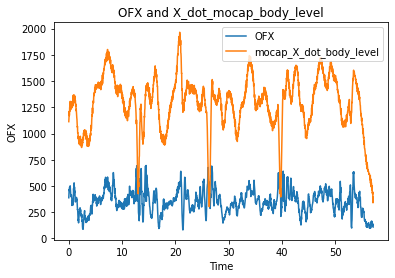

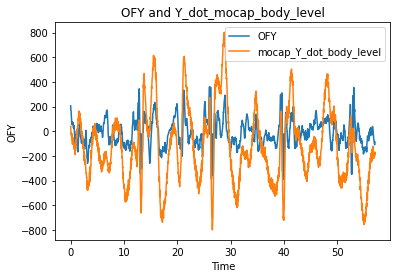

In [285]:
OFX=optic_flow_camera_x_mocap_interp.copy()
OFY=optic_flow_camera_y_mocap_interp.copy()

# apply a yaw rotation to the optic flow data using matrix multiplication
def rotate_optic_flow(OFX, OFY):
    """
    input: OFX, OFY
    output: rotated OFX, OFY
    """
    # apply a 180 degree rotation about x axis using the rotation matrix
    OFX = OFX*1
    OFY = OFY*np.cos(np.pi)

    # un yawing and rotating by 90 degrees
    OFY_rot = np.sin(np.pi/2) * OFX + np.cos(np.pi/2) * OFY
    OFX_rot = np.cos(np.pi/2) * OFX - np.sin(np.pi/2) * OFY
    return OFX_rot, OFY_rot


OFX_rot, OFY_rot = rotate_optic_flow(OFX, OFY)

plt.plot(mocap_time_shifted, OFX_rot,label='OFX')
plt.plot(mocap_time_shifted, np.multiply(velocity_body_x,1500),label='mocap_X_dot_body_level')
plt.title('OFX and X_dot_mocap_body_level')
plt.xlabel('Time')
plt.ylabel('OFX')
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, OFY_rot,label='OFY')
plt.plot(mocap_time_shifted, np.multiply(velocity_body_y,1500),label='mocap_Y_dot_body_level')
plt.title('OFY and Y_dot_mocap_body_level')
plt.xlabel('Time')
plt.ylabel('OFY')
plt.legend()
plt.show()


1713
Scalar (meters/pixel) X: 0.0006550889802214142
Scalar (meters/pixel) Y: 0.0007224214612360848


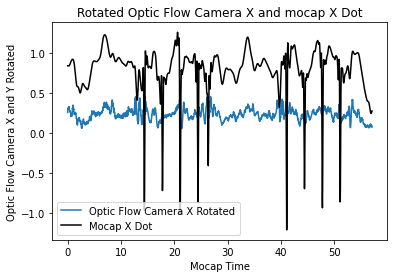

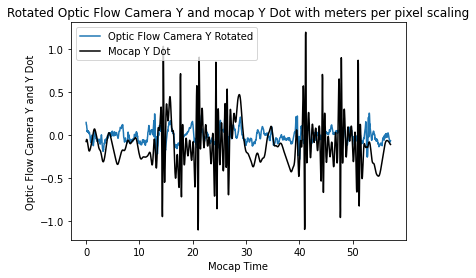

In [286]:
# Reshape the optic flow data to fit the linear regression model
OFX_rot_temp = np.array(OFX_rot)[:int(len(optic_flow_camera_x_mocap_interp)/1)].reshape(-1, 1)
OFY_rot_temp = np.array(OFY_rot)[:int(len(optic_flow_camera_x_mocap_interp)/1)].reshape(-1, 1)
print(len(OFY))
# Perform linear regression
modelX = LinearRegression()
modelX.fit(OFX_rot_temp, mocap_bl_X_dot[:int(len(optic_flow_camera_x_mocap_interp)/1)])

# The slope of the linear regression gives you the scalar (meters/pixel)
meters_per_pixel_X = modelX.coef_[0]
optic_flow_scalar_X = meters_per_pixel_X.copy()
print(f"Scalar (meters/pixel) X: {meters_per_pixel_X}")

modelY = LinearRegression()
modelY.fit(OFY_rot_temp, mocap_bl_Y_dot[:int(len(optic_flow_camera_x_mocap_interp)/1)])

# The slope of the linear regression gives you the scalar (meters/pixel)
meters_per_pixel_Y = modelY.coef_[0]
optic_flow_scalar_Y = meters_per_pixel_Y.copy()
print(f"Scalar (meters/pixel) Y: {meters_per_pixel_Y}")

# Plot the rotated optic flow data
plt.plot(mocap_time_shifted, np.multiply(OFX_rot,meters_per_pixel_X), label="Optic Flow Camera X Rotated")
plt.plot(mocap_time_shifted,np.multiply(mocap_bl_X_dot,1), label="Mocap X Dot",color='black')
# plt.plot(mocap_time, OFY_rot, label="Optic Flow Camera Y Rotated")
plt.title('Rotated Optic Flow Camera X and mocap X Dot')
plt.xlabel('Mocap Time')
plt.ylabel('Optic Flow Camera X and Y Rotated')
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, np.multiply(OFY_rot,meters_per_pixel_Y), label="Optic Flow Camera Y Rotated")
plt.plot(mocap_time_shifted,np.multiply(mocap_bl_Y_dot,1), label="Mocap Y Dot",color='black')
plt.title('Rotated Optic Flow Camera Y and mocap Y Dot with meters per pixel scaling')
plt.xlabel('Mocap Time')
plt.ylabel('Optic Flow Camera Y and Y Dot')
plt.legend()
plt.show()

# Stats model

                            OLS Regression Results                            
Dep. Variable:                    vel   R-squared:                       0.266
Model:                            OLS   Adj. R-squared:                  0.265
Method:                 Least Squares   F-statistic:                     619.4
Date:                Thu, 26 Jun 2025   Prob (F-statistic):          5.96e-117
Time:                        23:43:57   Log-Likelihood:                 1982.2
No. Observations:                1713   AIC:                            -3960.
Df Residuals:                    1711   BIC:                            -3950.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.2762      0.006     44.473      0.0

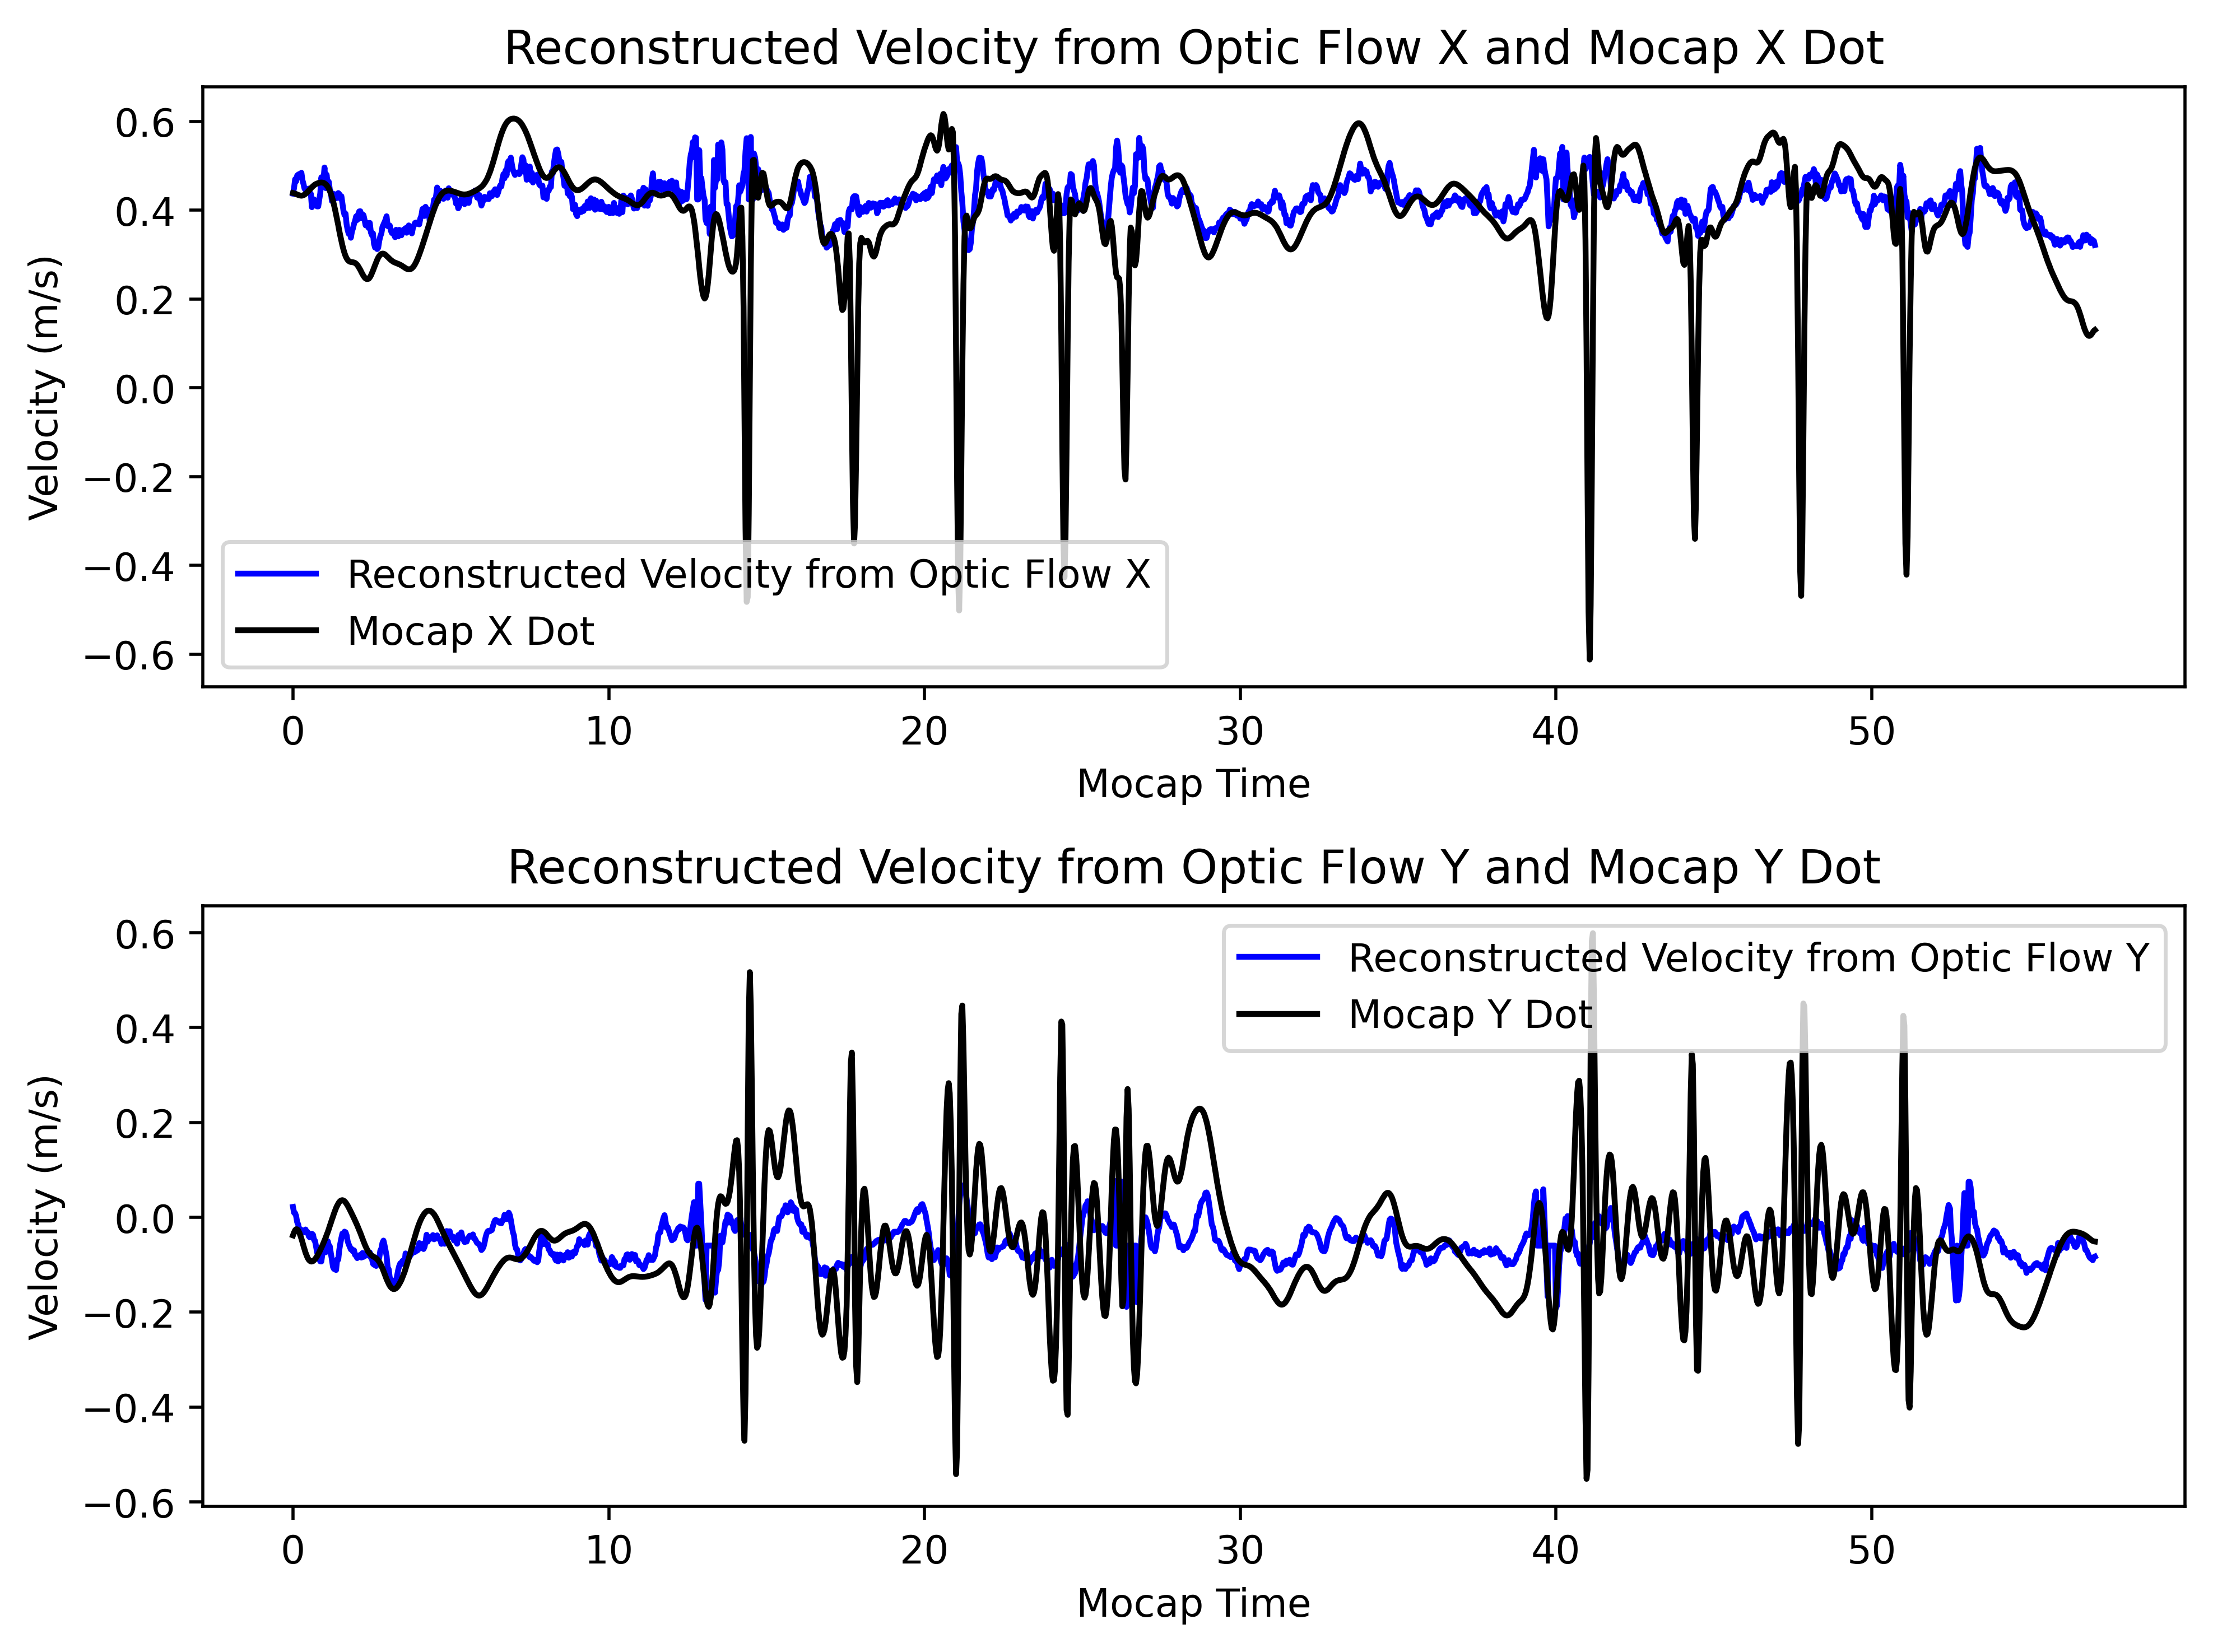

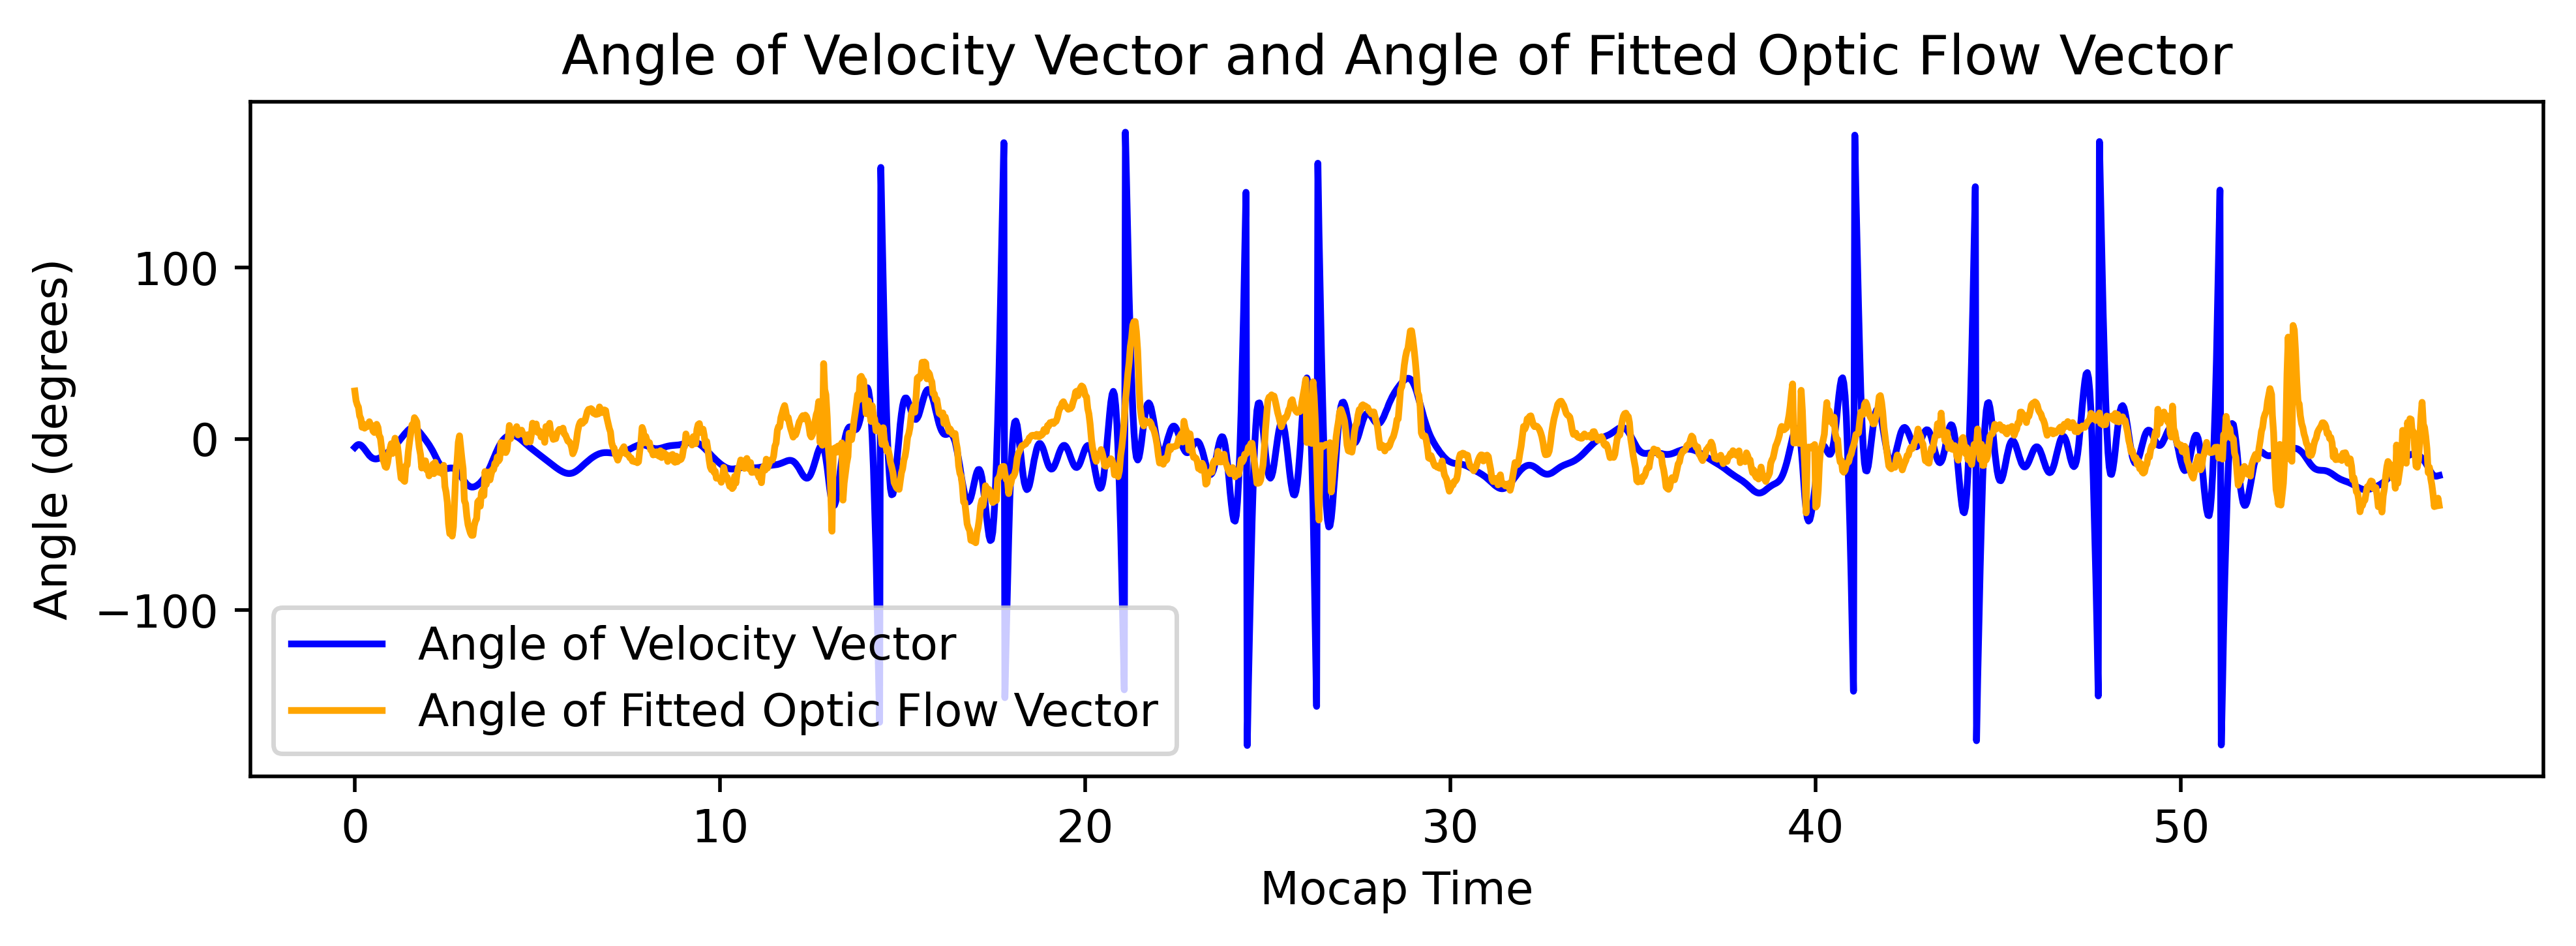

In [287]:
import pandas as pd
import statsmodels.formula.api as smf

# Create DataFrame for X-axis
df_X = pd.DataFrame({
    'flow': np.array(OFX_rot)[:len(optic_flow_camera_x_mocap_interp)],
    'vel': np.divide(velocity_body_x[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
})

# Run regression for X-axis
modelX = smf.ols('vel ~ flow', data=df_X).fit()
optic_flow_scalar_X = modelX.params['flow']
optic_flow_intercept_X = modelX.params['Intercept']
vel_from_optic_flow_X = optic_flow_scalar_X * np.array(OFX_rot)[:len(optic_flow_camera_x_mocap_interp)]+ optic_flow_intercept_X
print(modelX.summary())
print(f"Scalar (meters/pixel) X: {optic_flow_scalar_X}")

# Create DataFrame for Y-axis
df_Y = pd.DataFrame({
    'flow': np.array(OFY_rot)[:len(optic_flow_camera_x_mocap_interp)],
    'vel': np.divide(mocap_bl_Y_dot[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
})

# Run regression for Y-axis
modelY = smf.ols('vel ~ flow', data=df_Y).fit()
optic_flow_scalar_Y = modelY.params['flow']
optic_flow_intercept_Y = modelY.params['Intercept']
vel_from_optic_flow_Y = optic_flow_scalar_Y * np.array(OFY_rot)[:len(optic_flow_camera_x_mocap_interp)]+ optic_flow_intercept_Y
print(modelY.summary())
print(f"Scalar (meters/pixel) Y: {optic_flow_scalar_Y}")

# find the peaks in the mocap yaw rate data
from scipy.signal import find_peaks
positive_peaks, _ = find_peaks(mocap_Yaw_dot, height=0.1, distance=10)
negative_peaks, _ = find_peaks(-mocap_Yaw_dot, height=0.1, distance=10)
positive_peaks = np.array(positive_peaks, dtype=int)
negative_peaks = np.array(negative_peaks, dtype=int)


print("positive_peaks:", positive_peaks)
print("negative_peaks:", negative_peaks)

# plot the reconstructed velocity based on the optic flow data and the statsmodels
fig, ax = plt.subplots(2, 1, figsize=(8, 6), dpi=500)
# Plot X-axis
ax[0].plot(mocap_time_shifted, vel_from_optic_flow_X, label="Reconstructed Velocity from Optic Flow X", color='blue')
ax[0].plot(mocap_time_shifted, np.divide(mocap_bl_X_dot, mocap_Z), label="Mocap X Dot", color='black')
# ax[0].scatter(mocap_time_shifted[positive_peaks], np.divide(mocap_bl_X_dot, mocap_Z)[positive_peaks], color='red', zorder=5)
# ax[0].scatter(mocap_time_shifted[negative_peaks], np.divide(mocap_bl_X_dot, mocap_Z)[negative_peaks], color='red', zorder=5)
ax[0].set_title('Reconstructed Velocity from Optic Flow X and Mocap X Dot')
ax[0].set_xlabel('Mocap Time')
ax[0].set_ylabel('Velocity (m/s)')
ax[0].legend()
# Plot Y-axis
ax[1].plot(mocap_time_shifted, vel_from_optic_flow_Y, label="Reconstructed Velocity from Optic Flow Y", color='blue')
ax[1].plot(mocap_time_shifted, np.divide(mocap_bl_Y_dot, mocap_Z), label="Mocap Y Dot", color='black')
# ax[1].scatter(mocap_time_shifted[positive_peaks], np.divide(mocap_bl_Y_dot, mocap_Z)[positive_peaks], color='red', zorder=5)
# ax[1].scatter(mocap_time_shifted[negative_peaks], np.divide(mocap_bl_Y_dot, mocap_Z)[negative_peaks], color='red', zorder=5)
ax[1].set_title('Reconstructed Velocity from Optic Flow Y and Mocap Y Dot')
ax[1].set_xlabel('Mocap Time')
ax[1].set_ylabel('Velocity (m/s)')
ax[1].legend()
plt.tight_layout()
plt.show()

# angle of velocity vector
Angle_of_velocity = np.arctan2(mocap_bl_Y_dot, mocap_bl_X_dot)
# angle of the fitted optic flow vector
Angle_of_optic_flow = np.arctan2(OFY_rot, OFX_rot)
# plot the angle of the velocity vector and the angle of the fitted optic flow vector
fig, ax = plt.subplots(figsize=(8, 3), dpi=500)
ax.plot(mocap_time_shifted, np.rad2deg(Angle_of_velocity), label="Angle of Velocity Vector", color='blue')
ax.plot(mocap_time_shifted, np.rad2deg(Angle_of_optic_flow), label="Angle of Fitted Optic Flow Vector", color='orange')
# ax.scatter(mocap_time_shifted[positive_peaks], np.rad2deg(Angle_of_velocity[positive_peaks]), color='red', zorder=5)
# ax.scatter(mocap_time_shifted[negative_peaks], np.rad2deg(Angle_of_velocity[negative_peaks]), color='red', zorder=5)
ax.set_title('Angle of Velocity Vector and Angle of Fitted Optic Flow Vector')
ax.set_xlabel('Mocap Time')
ax.set_ylabel('Angle (degrees)')
ax.legend()
plt.tight_layout()
plt.show()


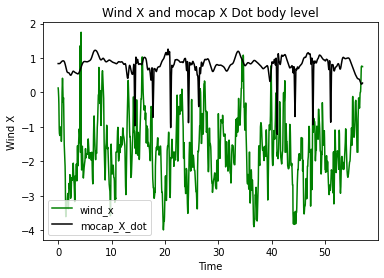

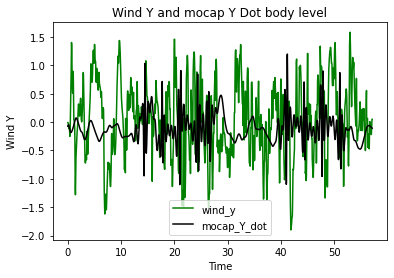

In [288]:
wind_time = data['trisonica']['rosbagTimestamp']/1e9/2
wind_time_shifted = wind_time - wind_time[0]
wind_x = data['trisonica']['westeast']
wind_y = -1*data['trisonica']['northsouth']

# interpolate wind data to mocap time
wind_x_mocap_interp = interpolate_data(wind_time, wind_x, mocap_time)
wind_y_mocap_interp = interpolate_data(wind_time, wind_y, mocap_time)

wind_x_mocap_interp = remove_outliers(wind_x_mocap_interp,threshold=4.0)
wind_y_mocap_interp = remove_outliers(wind_y_mocap_interp,threshold=4.0)

# # # filter out large spikes in the wind data
# if FLAG_FILE == "con_vel" or FLAG_FILE == "con_vel_con_yaw":
#     wind_x_mocap_interp[np.abs(wind_x_mocap_interp - np.median(wind_x_mocap_interp)) > 3 * np.std(wind_x_mocap_interp)] = np.median(wind_x_mocap_interp)
#     wind_y_mocap_interp[np.abs(wind_y_mocap_interp - np.median(wind_y_mocap_interp)) > 3 * np.std(wind_y_mocap_interp)] = np.median(wind_y_mocap_interp)


plt.plot(mocap_time_shifted, wind_x_mocap_interp,label='wind_x',color='green')
# plt.plot(wind_time_shifted, wind_x,label='wind_x',color='green')
# plt.plot(mocap_time_shifted, np.multiply(OFX_rot,meters_per_pixel_X), label="Optic Flow Camera X Rotated",color='blue')
plt.plot(mocap_time_shifted, mocap_bl_X_dot,label='mocap_X_dot',color='black')
plt.title('Wind X and mocap X Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind X')
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, wind_y_mocap_interp,label='wind_y',color='green')
# plt.plot(mocap_time_shifted, np.multiply(OFY_rot,meters_per_pixel_Y), label="Optic Flow Camera Y Rotated",color='blue')
plt.plot(mocap_time_shifted, mocap_bl_Y_dot,label='mocap_Y_dot',color='black')
plt.title('Wind Y and mocap Y Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind Y')
plt.legend()
plt.show()

# mocap groung speed and direction
mocap_ground_speed = np.sqrt(np.square(mocap_bl_X_dot) + np.square(mocap_bl_Y_dot))
mocap_ground_direction = np.arctan2(mocap_bl_Y_dot, mocap_bl_X_dot)
wind_ground_speed = np.sqrt(np.square(wind_x_mocap_interp) + np.square(wind_y_mocap_interp))
wind_ground_direction = np.arctan2(wind_y_mocap_interp, wind_x_mocap_interp)

# plt.plot(mocap_time_shifted, mocap_ground_speed,label='mocap_ground_speed',color='black')
# plt.plot(mocap_time_shifted, wind_ground_speed,label='wind_speed',color='green')
# plt.title('Ground Speed')
# plt.xlabel('Time')
# plt.ylabel('Speed')
# plt.legend()
# plt.show()

# plt.plot(mocap_time_shifted, mocap_ground_direction,label='mocap_ground_direction',color='black')
# # plt.plot(mocap_time_shifted, wind_ground_direction,label='wind_direction',color='green')
# plt.title('Ground Direction')
# plt.xlabel('Time')
# plt.ylabel('Direction')
# plt.legend()
# plt.show()


Scalar X: 0.025442237037225347
Scalar Y: -0.03036613744912535


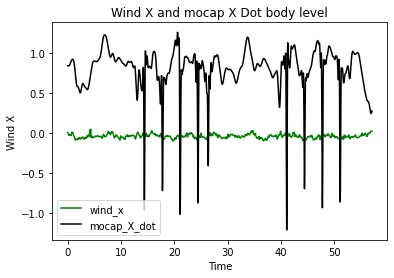

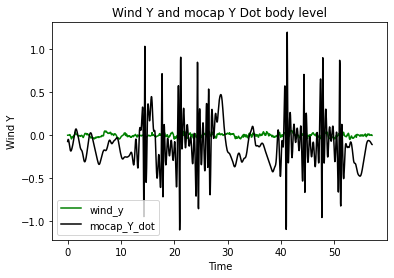

In [289]:

start_int_x = 0
stop_int_x = 4/4
start_int_y = 0
stop_int_y = 4/4

wind_body_level_x, wind_body_level_y =np.array(wind_x_mocap_interp).reshape(-1, 1), np.array(wind_y_mocap_interp).reshape(-1, 1)

wind_body_level_x_temp, wind_body_level_y_temp =np.array(wind_x_mocap_interp)[int(len(wind_x_mocap_interp)*start_int_x):int(len(wind_x_mocap_interp)*stop_int_x)].reshape(-1, 1), np.array(wind_y_mocap_interp).reshape(-1, 1)

wind_body_level_mag_temp = np.array(wind_ground_speed).reshape(-1, 1)

#perform linear regression on the wind data
model_wind_x = LinearRegression()
model_wind_x.fit(wind_body_level_x_temp, mocap_bl_X_dot[int(len(wind_x_mocap_interp)*start_int_x):int(len(wind_x_mocap_interp)*stop_int_x)])

# The slope of the linear regression gives you the scalar
wind_scalar_x = model_wind_x.coef_[0]
# print(model_wind_x.coef_)
print(f"Scalar X: {wind_scalar_x}")

model_wind_y = LinearRegression()
model_wind_y.fit(wind_body_level_y_temp, mocap_bl_Y_dot)

# The slope of the linear regression gives you the scalar
wind_scalar_y = model_wind_y.coef_[0]
print(f"Scalar Y: {wind_scalar_y}")

model_wind_mag = LinearRegression()
model_wind_mag.fit(wind_body_level_mag_temp, mocap_ground_speed)

# The slope of the linear regression gives you the scalar
wind_scalar_mag = model_wind_mag.coef_[0]
# print(f"Scalar (unitless) Mag: {wind_scalar_mag}")


# #mocap xy plot
# plt.plot(mocap_X, mocap_Y,label='mocap')
# plt.scatter(mocap_X, mocap_Y, label='start', c=mocap_time_shifted)
# plt.xlabel('X')
# plt.ylabel('Y')
# plt.title('XY')
# plt.colorbar()
# plt.show()

# #plot mocap yaw
# plt.plot(mocap_time_shifted, mocap_Yaw,label='Yaw')
# plt.scatter(mocap_time_shifted, mocap_Yaw, label='Yaw', c=mocap_time_shifted)
# plt.title('Yaw')
# plt.xlabel('Time')
# plt.ylabel('Yaw')
# plt.legend()
# plt.colorbar()
# plt.show()

# plt.plot(mocap_time_shifted, np.multiply(wind_body_level_x,-0.2410)+0.0530,label='wind_x',color='green')
plt.plot(mocap_time_shifted, np.multiply(wind_body_level_x,wind_scalar_x),label='wind_x',color='green')
plt.plot(mocap_time_shifted, mocap_bl_X_dot,label='mocap_X_dot',color='black')
plt.title('Wind X and mocap X Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind X')
# plt.ylim(-1.5,1.5)
plt.legend()
plt.show()

# plt.plot(mocap_time_shifted, np.multiply(wind_body_level_y,-0.1438)+-0.2180,label='wind_y',color='green')
plt.plot(mocap_time_shifted, np.multiply(wind_body_level_y,wind_scalar_y),label='wind_y',color='green')
plt.plot(mocap_time_shifted, mocap_bl_Y_dot,label='mocap_Y_dot',color='black')
plt.title('Wind Y and mocap Y Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind Y')
plt.legend()
plt.show()

# plt.plot(mocap_time_shifted, np.multiply(wind_ground_speed,wind_scalar_mag),label='wind_speed')
# plt.plot(mocap_time_shifted, mocap_ground_speed,label='mocap_ground_speed')
# plt.title('Ground Speed')
# plt.xlabel('Time')
# plt.ylabel('Speed')
# plt.legend()
# plt.show()


# stats model

                            OLS Regression Results                            
Dep. Variable:                    vel   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     11.67
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           0.000651
Time:                        23:44:01   Log-Likelihood:                -331.23
No. Observations:                1713   AIC:                             666.5
Df Residuals:                    1711   BIC:                             677.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8302      0.014     57.933      0.0

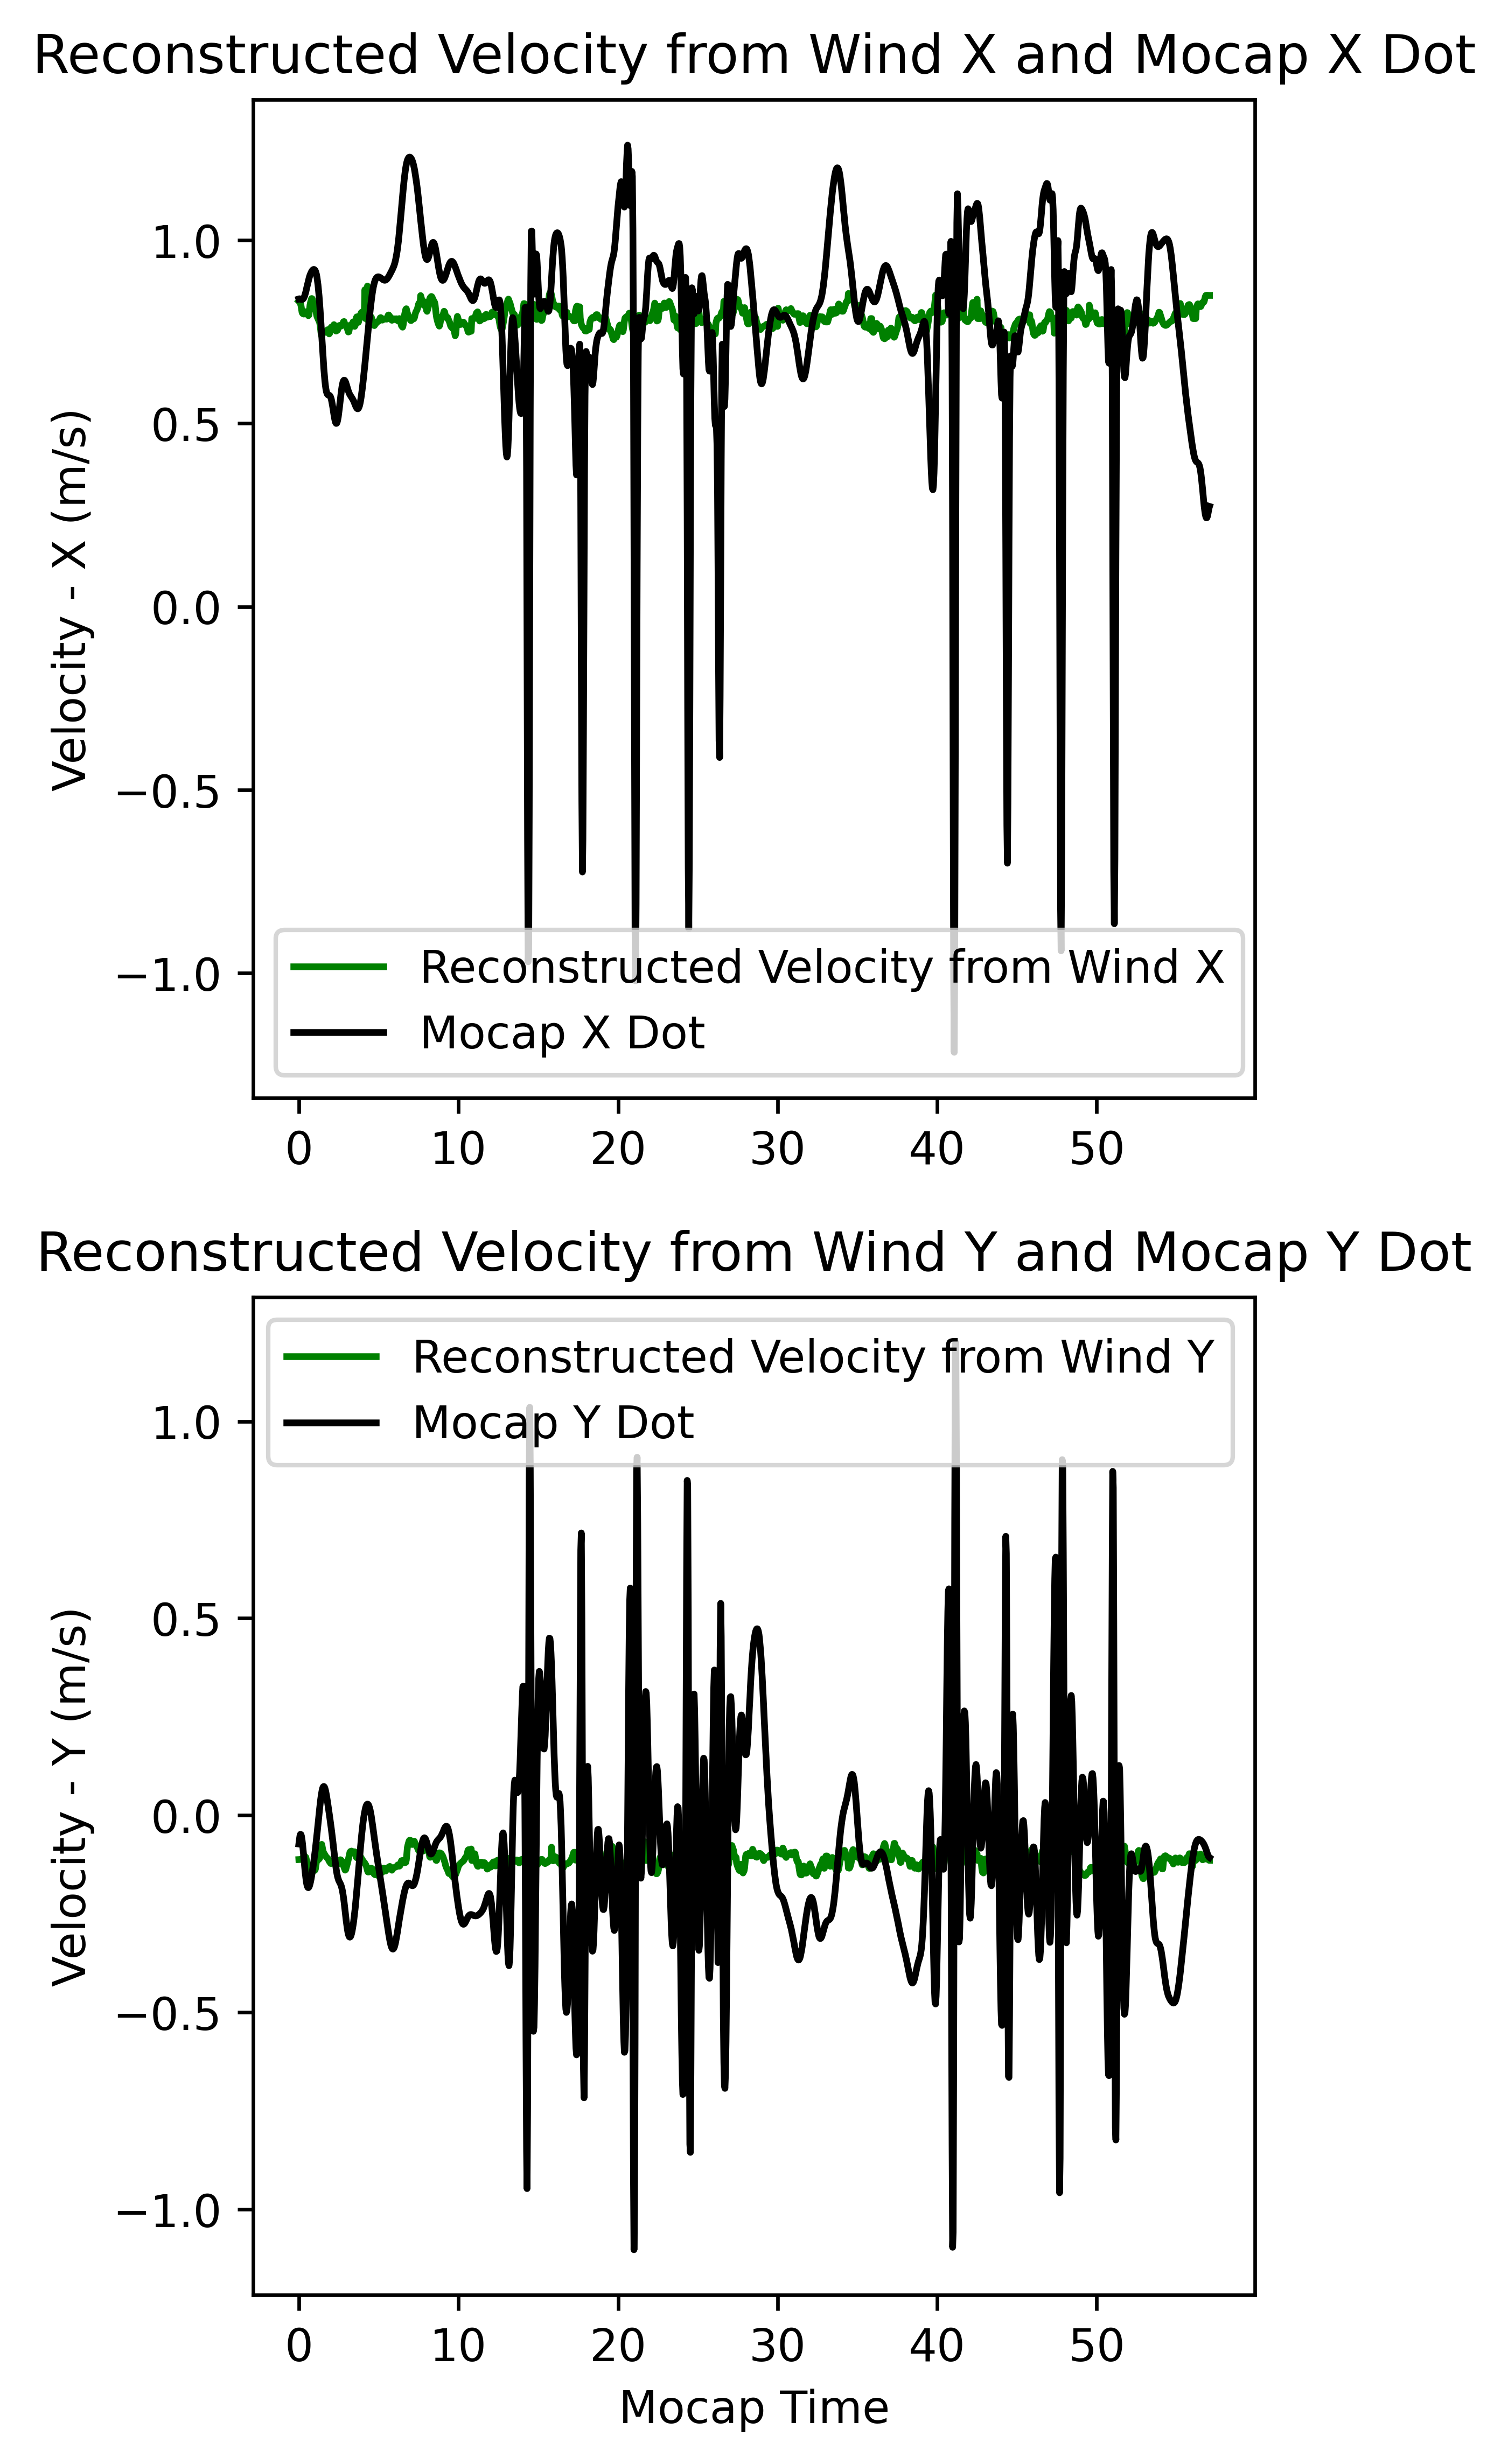

In [290]:
import pandas as pd
import statsmodels.formula.api as smf




# X-axis regression (full range)
df_wind_x = pd.DataFrame({
    'wind': np.array(wind_x_mocap_interp),
    'vel': mocap_bl_X_dot
})
model_wind_x = smf.ols('vel ~ wind', data=df_wind_x).fit()
wind_scalar_x = model_wind_x.params['wind']
wind_intercept_x = model_wind_x.params['Intercept']
vel_from_wind_x = wind_scalar_x * np.array(wind_x_mocap_interp) + wind_intercept_x
# vel_from_wind_x = -0.2617 * np.array(wind_x_mocap_interp) + 0.1422
print(model_wind_x.summary())
print(f"Scalar X: {wind_scalar_x}")

# Y-axis regression (full range)
df_wind_y = pd.DataFrame({
    'wind': np.array(wind_y_mocap_interp),
    'vel': mocap_bl_Y_dot
})
model_wind_y = smf.ols('vel ~ wind', data=df_wind_y).fit()
wind_scalar_y = model_wind_y.params['wind']
wind_intercept_y = model_wind_y.params['Intercept']
vel_from_wind_y = wind_scalar_y * np.array(wind_y_mocap_interp) + wind_intercept_y
# vel_from_wind_y = -0.2316  * np.array(wind_y_mocap_interp) -0.0054
print(model_wind_y.summary())
print(f"Scalar Y: {wind_scalar_y}")

# Magnitude regression (full range)
df_wind_mag = pd.DataFrame({
    'wind': np.array(wind_ground_speed),
    'vel': mocap_ground_speed
})
model_wind_mag = smf.ols('vel ~ wind', data=df_wind_mag).fit()
wind_scalar_mag = model_wind_mag.params['wind']
wind_intercept_mag = model_wind_mag.params['Intercept']
vel_from_wind_mag = wind_scalar_mag * np.array(wind_ground_speed) + wind_intercept_mag
print(model_wind_mag.summary())
print(f"Scalar Mag: {wind_scalar_mag}")

# Plot the reconstructed velocity based on the wind data and the statsmodels
fig, ax = plt.subplots(2, 1, figsize=(4, 9), dpi=600)
# Plot X-axis
ax[0].plot(mocap_time_shifted, vel_from_wind_x, label="Reconstructed Velocity from Wind X", color='green')
ax[0].plot(mocap_time_shifted, mocap_bl_X_dot, label="Mocap X Dot", color='black')
ax[0].set_title('Reconstructed Velocity from Wind X and Mocap X Dot')
# ax[0].set_xlabel('Mocap Time')
ax[0].set_ylabel('Velocity - X (m/s)')
ax[0].legend()
# Plot Y-axis
ax[1].plot(mocap_time_shifted, vel_from_wind_y, label="Reconstructed Velocity from Wind Y", color='green')
ax[1].plot(mocap_time_shifted, mocap_bl_Y_dot, label="Mocap Y Dot", color='black')
ax[1].set_title('Reconstructed Velocity from Wind Y and Mocap Y Dot')
ax[1].set_xlabel('Mocap Time')
ax[1].set_ylabel('Velocity - Y (m/s)')
ax[1].legend()




# RC Out ~ PWM

In [291]:
data['mavros/rc/out']
# split the data in header "channels" into individual columns named PWM1, PWM2, PWM3, PWM4 (only take the first 4 channels) each colum should be a float not a string
rc_time = data['mavros/rc/out']['rosbagTimestamp']/1e9/2
rc_time_shifted = rc_time - rc_time[0]
rc_channels = data['mavros/rc/out']['channels']
rc_channels = rc_channels.str.split(',', expand=True)
# remove "[" from the first column
rc_channels[0] = rc_channels[0].str.replace('[','')
rc_channels = rc_channels.iloc[:, :4]
rc_channels = rc_channels.astype(float)
PX4_1 = rc_channels[0]
PX4_2 = rc_channels[1]
PX4_3 = rc_channels[2]
PX4_4 = rc_channels[3]



/tmp/ipykernel_37935/2308055145.py:8: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  rc_channels[0] = rc_channels[0].str.replace('[','')


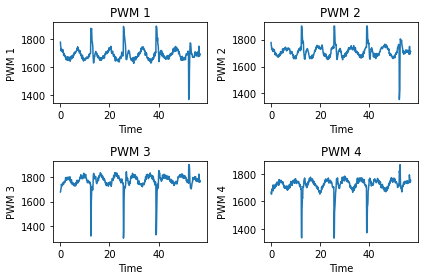

In [292]:
# pwm_1 = PX4_3
# pwm_2 = PX4_1
# pwm_3 = PX4_4
# pwm_4 = PX4_2

pwm_1 = PX4_1
pwm_2 = PX4_2
pwm_3 = PX4_3
pwm_4 = PX4_4
# 2x2 plot of the pwm data
plt.subplot(2, 2, 1)
plt.plot(rc_time_shifted, pwm_1)
plt.title('PWM 1')
plt.xlabel('Time')
plt.ylabel('PWM 1')

plt.subplot(2, 2, 2)
plt.plot(rc_time_shifted, pwm_2)
plt.title('PWM 2')
plt.xlabel('Time')
plt.ylabel('PWM 2')

plt.subplot(2, 2, 3)
plt.plot(rc_time_shifted, pwm_3)
plt.title('PWM 3')
plt.xlabel('Time')
plt.ylabel('PWM 3')

plt.subplot(2, 2, 4)
plt.plot(rc_time_shifted, pwm_4)
plt.title('PWM 4')
plt.xlabel('Time')
plt.ylabel('PWM 4')

plt.tight_layout()
plt.show()

# Get the final values fir all the measured data

## since mocap is the fastes we will interpolate to that

### Mocap Final

In [293]:
X_TRUE = mocap_X
X_DOT_G_TRUE = mocap_X_dot
X_DOT_BL_TRUE = mocap_bl_X_dot
Y_TRUE = mocap_Y
Y_DOT_G_TRUE = mocap_Y_dot
Y_DOT_BL_TRUE = mocap_bl_Y_dot
Z_TRUE = mocap_Z
Z_DOT_G_TRUE = mocap_Z_dot
Z_DOT_BL_TRUE = mocap_bl_Z_dot
Roll_TRUE = mocap_Roll
Pitch_TRUE = mocap_Pitch
Yaw_TRUE = mocap_Yaw
OMEGA_X_TRUE = mocap_Omega_x
OMEGA_Y_TRUE = mocap_Omega_y
OMEGA_Z_TRUE = mocap_Omega_z

# put into a dataframe
df_all = pd.DataFrame({
    'X_TRUE': X_TRUE,
    'X_DOT_G_TRUE': X_DOT_G_TRUE,
    'X_DOT_BL_TRUE': X_DOT_BL_TRUE,
    'Y_TRUE': Y_TRUE,
    'Y_DOT_G_TRUE': Y_DOT_G_TRUE,
    'Y_DOT_BL_TRUE': Y_DOT_BL_TRUE,
    'Z_TRUE': Z_TRUE,
    'Z_DOT_G_TRUE': Z_DOT_G_TRUE,
    'Z_DOT_BL_TRUE': Z_DOT_BL_TRUE,
    'Roll_TRUE': Roll_TRUE,
    'Pitch_TRUE': Pitch_TRUE,
    'Yaw_TRUE': Yaw_TRUE,
    'OMEGA_X_TRUE': OMEGA_X_TRUE,
    'OMEGA_Y_TRUE': OMEGA_Y_TRUE,
    'OMEGA_Z_TRUE': OMEGA_Z_TRUE
})

# IMU Final

In [294]:
IMU_ROLL = interpolate_data(imu_time, imu_Roll, mocap_time)
IMU_PITCH = interpolate_data(imu_time, imu_Pitch, mocap_time)
IMU_YAW = interpolate_data(imu_time, imu_Yaw, mocap_time)
IMU_ROLL_DOT = interpolate_data(imu_time, imu_Roll_dot, mocap_time)
IMU_PITCH_DOT = interpolate_data(imu_time, imu_Pitch_dot, mocap_time)
IMU_YAW_DOT = interpolate_data(imu_time, imu_Yaw_dot, mocap_time)
# IMU_OMEGA_X = interpolate_data(imu_time, imu_omega_x, mocap_time)
IMU_OMEGA_X = mocap_Omega_x
# IMU_OMEGA_Y = interpolate_data(imu_time, imu_omega_y, mocap_time)
IMU_OMEGA_Y = mocap_Omega_y
# IMU_OMEGA_Z = interpolate_data(imu_time, imu_omega_z, mocap_time)
IMU_OMEGA_Z = mocap_Omega_z
# IMU_ACC_BL_X = interpolate_data(imu_time, acc_x_body_level, mocap_time)
IMU_ACC_BL_X = accleration_body_x
# IMU_ACC_BL_Y = interpolate_data(imu_time, acc_y_body_level, mocap_time)
IMU_ACC_BL_Y = accleration_body_y
# IMU_ACC_BL_Z = interpolate_data(imu_time, acc_z_body_level, mocap_time)
IMU_ACC_BL_Z = accleration_body_z
print(np.shape(acc_z_body_level))

# add to df_all
df_all['IMU_ROLL'] = IMU_ROLL
df_all['IMU_PITCH'] = IMU_PITCH
df_all['IMU_YAW'] = IMU_YAW
df_all['IMU_ROLL_DOT'] = IMU_ROLL_DOT
df_all['IMU_PITCH_DOT'] = IMU_PITCH_DOT
df_all['IMU_YAW_DOT'] = IMU_YAW_DOT
df_all['IMU_OMEGA_X'] = IMU_OMEGA_X
df_all['IMU_OMEGA_Y'] = IMU_OMEGA_Y
df_all['IMU_OMEGA_Z'] = IMU_OMEGA_Z
df_all['IMU_ACC_BL_X'] = IMU_ACC_BL_X
df_all['IMU_ACC_BL_Y'] = IMU_ACC_BL_Y
df_all['IMU_ACC_BL_Z'] = IMU_ACC_BL_Z
# df_all.to_csv('df_all.csv', index=False)

(2854,)


# Wind sensor fianl

In [295]:
Wind_BL_X = np.ravel(np.array(wind_body_level_x))
Wind_BL_Y = np.ravel(np.array(wind_body_level_y))
Wind_BL_X_f = 1*wind_scalar_x
# Wind_BL_X_f = -0.2580
Wind_BL_X_offset = wind_intercept_x
# Wind_BL_X_offset = 0.1175
Wind_BL_Y_f = 1*wind_scalar_y
# Wind_BL_Y_f = -0.2478
Wind_BL_Y_offset = wind_intercept_y
# Wind_BL_Y_offset = -0.1869
# Wind_BL_X_Scaled = np.multiply(Wind_BL_X, Wind_BL_X_f) + Wind_BL_X_offset
Wind_BL_X_Scaled = Wind_BL_X
# Wind_BL_Y_Scaled = np.multiply(Wind_BL_Y, Wind_BL_Y_f) + Wind_BL_Y_offset
Wind_BL_Y_Scaled = Wind_BL_Y
Wind_BL_A = np.sqrt(np.square(Wind_BL_X_Scaled) + np.square(Wind_BL_Y_Scaled))
Wind_BL_Gamma = np.arctan2(Wind_BL_Y_Scaled, Wind_BL_X_Scaled)

# add to df_all
df_all['Wind_BL_X'] = Wind_BL_X
df_all['Wind_BL_Y'] = Wind_BL_Y
df_all['Wind_BL_X_Scaled'] = Wind_BL_X_Scaled
df_all['Wind_BL_Y_Scaled'] = Wind_BL_Y_Scaled
df_all['Wind_BL_A'] = Wind_BL_A
df_all['Wind_BL_Gamma'] = Wind_BL_Gamma


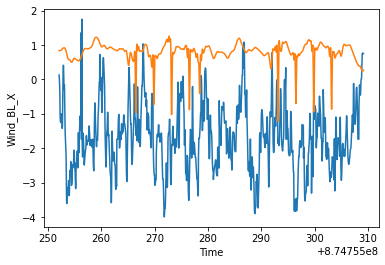

<function matplotlib.pyplot.show(*args, **kw)>

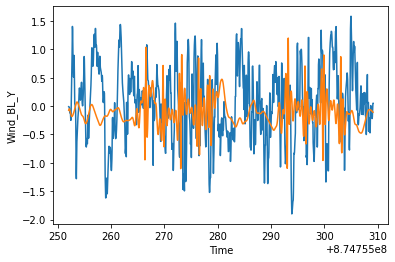

In [296]:
plt.plot(mocap_time, Wind_BL_X_Scaled,label='Wind_X_f')
plt.plot(mocap_time, X_DOT_BL_TRUE,label='X_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('Wind_BL_X')
plt.show()

plt.plot(mocap_time, Wind_BL_Y_Scaled,label='Wind_Y_f')
plt.plot(mocap_time, Y_DOT_BL_TRUE,label='Y_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('Wind_BL_Y')
plt.show

# optic flow final

In [297]:
OF_BL_X, OF_BL_Y = rotate_optic_flow(optic_flow_camera_x_mocap_interp, optic_flow_camera_y_mocap_interp)
OF_BL_X_f = optic_flow_scalar_X.copy()
print(OF_BL_X_f)
OF_BL_X_offset = optic_flow_intercept_X.copy()
print(OF_BL_X_offset)
OF_BL_Y_f = optic_flow_scalar_Y
OF_BL_Y_offset = optic_flow_intercept_Y
OF_BL_X_Scaled = np.multiply(OF_BL_X,OF_BL_X_f) + OF_BL_X_offset
OF_BL_Y_Scaled = np.multiply(OF_BL_Y,OF_BL_Y_f) + OF_BL_Y_offset

# add to df_all
df_all['OF_BL_X'] = OF_BL_X
df_all['OF_BL_Y'] = OF_BL_Y
df_all['OF_BL_X_Scaled'] = OF_BL_X_Scaled
df_all['OF_BL_Y_Scaled'] = OF_BL_Y_Scaled

0.0004151906251951257
0.2762459353547368


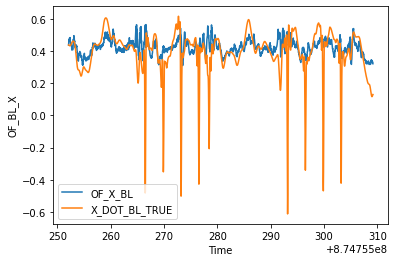

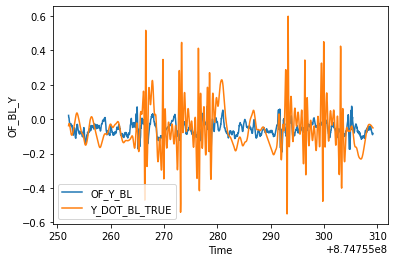

Standard deviation of OF_BL_X_Scaled - np.divide(X_DOT_BL_TRUE,Z_TRUE): 0.14201787289315138
Standard deviation of OF_BL_Y_Scaled - np.divide(Y_DOT_BL_TRUE,Z_TRUE): 0.12231334457080777


In [298]:
plt.plot(mocap_time, OF_BL_X_Scaled,label='OF_X_BL')
plt.plot(mocap_time, np.divide(X_DOT_BL_TRUE,Z_TRUE),label='X_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('OF_BL_X')
plt.legend()
plt.show()

plt.plot(mocap_time, OF_BL_Y_Scaled,label='OF_Y_BL')
plt.plot(mocap_time, np.divide(Y_DOT_BL_TRUE,Z_TRUE),label='Y_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('OF_BL_Y')
plt.legend()
plt.show()

# calculate the standard deviation of OF_BL_X_Scaled -np.divide(X_DOT_BL_TRUE,Z_TRUE) and print it
std_dev_x = np.std(OF_BL_X_Scaled-np.divide(X_DOT_BL_TRUE,Z_TRUE))
print('Standard deviation of OF_BL_X_Scaled - np.divide(X_DOT_BL_TRUE,Z_TRUE):', std_dev_x)
std_dev_y = np.std(OF_BL_Y_Scaled-np.divide(Y_DOT_BL_TRUE,Z_TRUE))
print('Standard deviation of OF_BL_Y_Scaled - np.divide(Y_DOT_BL_TRUE,Z_TRUE):', std_dev_y)

# plt.plot(mocap_time, OF_BL_X_Scaled-np.divide(X_DOT_BL_TRUE,Z_TRUE),label='OF_BL_X-X_DOT_BL')

# PWM Final

In [299]:
PWM_1 = (interpolate_data(rc_time, pwm_1, mocap_time)-1150)/1000*9.81
PWM_2 = (interpolate_data(rc_time, pwm_2, mocap_time)-1150)/1000*9.81
PWM_3 = (interpolate_data(rc_time, pwm_3, mocap_time)-1150)/1000*9.81
PWM_4 = (interpolate_data(rc_time, pwm_4, mocap_time)-1150)/1000*9.81

# add to df_all
df_all['PWM_1'] = PWM_1
df_all['PWM_2'] = PWM_2
df_all['PWM_3'] = PWM_3
df_all['PWM_4'] = PWM_4

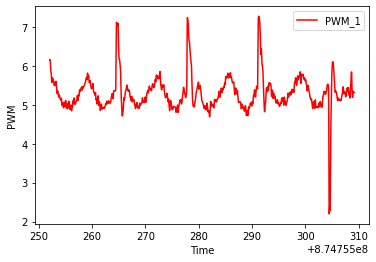

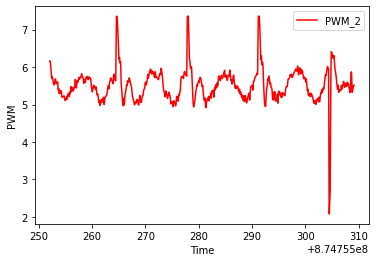

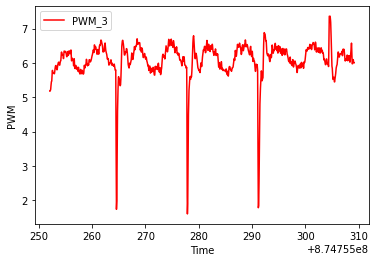

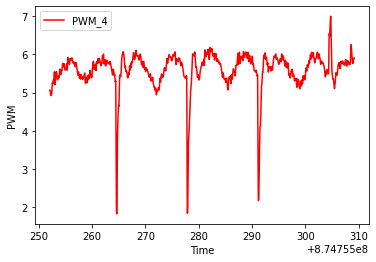

In [300]:
plt.plot(mocap_time, PWM_1,label='PWM_1',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()
plt.plot(mocap_time, PWM_2,label='PWM_2',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()
plt.plot(mocap_time, PWM_3,label='PWM_3',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()
plt.plot(mocap_time, PWM_4,label='PWM_4',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()

# Time

In [301]:
TIME_BL = mocap_time-mocap_time[0]
DT_BL=np.round(TIME_BL[1]-TIME_BL[0],2)
print(DT_BL)

# add to df_all
df_all['TIME_BL'] = TIME_BL

0.03


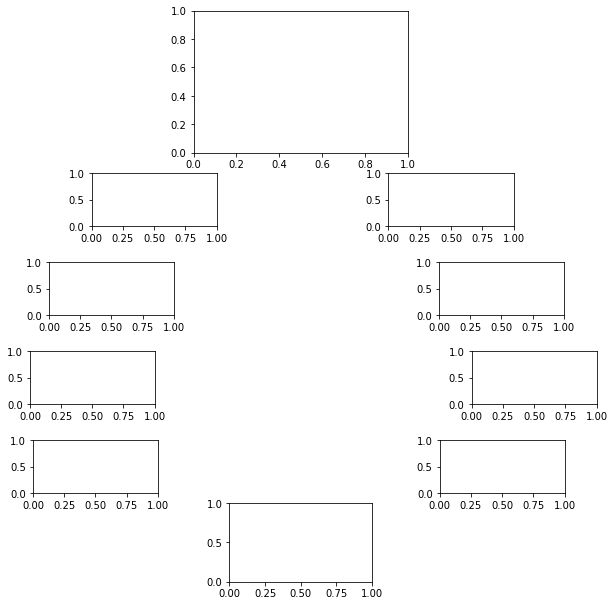

In [469]:
input_svg = '/home/austinlopez/Drone_AFRL/paper_figures/Fig_3.svg'
layout = fifi.svg_to_axes.FigureLayout(input_svg, autogenlayers=True, make_mplfigures=True, hide_layers=[])

In [470]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'mocap')]
duration = int(len(df_all)/4.7)
# Plot X and Y data
mocap_X = df_all['X_TRUE'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_Y = df_all['Y_TRUE'][0:duration]
mocap_psi = df_all['Yaw_TRUE'][0:duration]  # in degrees or radians? Should be radians for np.cos/sin
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_X, mocap_Y, label='Mocap X and Y', color='black', linewidth=0.5)

tri = np.array([[.1, 0], [-.05, -0.05], [-.05, 0.05]]) * 2
marker_step = 15
cmap = plt.get_cmap('viridis')  # Changed to 'viridis' for better visibility
norm = mpl.colors.Normalize(vmin=mocap_time.min(), vmax=mocap_time.max())
for i in range(0, len(mocap_time), marker_step):
    R = np.array([[np.cos(np.radians(mocap_psi[i])), -np.sin(np.radians(mocap_psi[i]))],
                  [np.sin(np.radians(mocap_psi[i])),  np.cos(np.radians(mocap_psi[i]))]])
    tri_r = tri @ R.T
    color = cmap(norm(mocap_time[i]))
    ax.fill(mocap_X[i] + tri_r[:, 0], mocap_Y[i] + tri_r[:, 1], color=color, alpha=0.8, edgecolor=None)
fifi.mpl_functions.adjust_spines(
    ax, [],
    yticks=[-2, 0, 2],
    xticks=[-4, -2, 0, 2],
    tick_length=3, linewidth=1,
    spine_locations={'left': 0, 'bottom': 0}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# set ticks to off and label off
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(axis='both', which='both', length=0)
ax.set_aspect('equal', adjustable='box')
ax.set_title('Mocap Trajectory')
# ax.set_xlabel('X')
# ax.set_ylabel('Y')
ax.set_xlim([-4, 2])
ax.set_ylim([-2, 2])
# add black line from -3.5 to -2.5
ax.plot([-3.75, -2.75], [1, 1], color='black', linewidth=3)
# text just above the black line saying 1m 
ax.text(-3.25, 1.15, '1 m', fontsize=12, color='black', ha='center')
# add black box around the plot with 4 lines
# ax.plot([-3.9, -3.9, 1.9, 1.9, -3.9], [-1.9, 1.9, 1.9, -1.9, -1.9], color='black', linewidth=3.5)
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

In [471]:
Flag =  False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'wind_x')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
wind_x =  df_all['Wind_BL_X_Scaled'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, wind_x, label='Wind X', color='purple', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[-5, 0, 5],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# set ticks to off and label off
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$W_{a,x}$ '+r'[$\frac{m}{s}$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([-5, 5])
# add black line from -3.5 to -2.5
ax.plot([.5, 2.5], [4, 4], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 4.65, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [472]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'wind_y')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
wind_x =  df_all['Wind_BL_X_Scaled'][0:duration]  # Adjusted to use only the first 'duration' entries
wind_y =  df_all['Wind_BL_Y_Scaled'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, wind_y, label='Wind Y', color='purple', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[-5, 0, 5],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# set ticks to off and label off
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$W_{a,y}$ '+r'[$\frac{m}{s}$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([-5, 5])
ax.plot([.5, 2.5], [4, 4], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 4.65, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [473]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'm4')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
PWM4 =  df_all['PWM_4'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, PWM4, label='PWM 4', color='red', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[4, 6, 8],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# set ticks to off and label off
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$PWM_{4}$ '+r'[$-$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([4, 8])
ax.plot([.5, 2.5], [7, 7], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 7.25, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [474]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'm2')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
PWM2 =  df_all['PWM_2'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, PWM2, label='PWM 2', color='orange', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[4, 6, 8],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# set ticks to off and label off
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$PWM_{2}$ '+r'[$-$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([4, 8])
ax.plot([.5, 2.5], [7, 7], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 7.25, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [475]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'm1')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
PWM1 =  df_all['PWM_1'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, PWM1, label='PWM 1', color='orange', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[4, 6, 8],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# set ticks to off and label off
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$PWM_{1}$ '+r'[$-$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([4, 8])
ax.plot([.5, 2.5], [7, 7], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 7.25, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [476]:
Flag =  False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'm3')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
PWM3 =  df_all['PWM_3'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, PWM3, label='PWM 3', color='red', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[4, 6, 8],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# keep ticks but remove labels
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$PWM_{3}$ '+r'[$-$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([4, 8])
ax.plot([.5, 2.5], [7, 7], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 7.25, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [477]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'Acc_x')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
acc_x_body_level = df_all['IMU_ACC_BL_X'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, acc_x_body_level, label='Acc X', color='cyan', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[-3, 0, 3],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# keep ticks but remove labels
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$A_{x}$ '+r'[$\frac{m}{s^{2}}$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([-3, 3])
ax.plot([.5, 2.5], [2, 2], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 2.25, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [478]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'Acc_y')]
duration = int(len(df_all)/4.7)
print(f"Duration: {duration} entries at a total time of {df_all['TIME_BL'][duration-1]} seconds")
# Plot X and Y data
acc_y_body_level = df_all['IMU_ACC_BL_Y'][0:duration]  # Adjusted to use only the first 'duration' entries
mocap_time = df_all['TIME_BL'][0:duration]  # Adjusted to use only the first 'duration' entries
ax.plot(mocap_time, acc_y_body_level, label='Acc Y', color='cyan', linewidth=1)


fifi.mpl_functions.adjust_spines(
    ax, ['bottom', 'left'],
    yticks=[-3, 0, 3],
    xticks=[0, 4, 8, 12],
    tick_length=3, linewidth=1,
    spine_locations={'left': 3, 'bottom': 3}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# keep ticks but remove labels
ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$A_{y}$ '+r'[$\frac{m}{s^{2}}$]')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
ax.set_xlim([0, 12])
ax.set_ylim([-3, 3])
ax.plot([.5, 2.5], [2, 2], color='black', linewidth=3)
# text just above the black line saying 2s
ax.text(1.5, 2.25, '2 s', fontsize=12, color='black', ha='center')
if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

Duration: 364 entries at a total time of 12.098055720329285 seconds


In [479]:
Flag = False
triangle_scale = 1.0  # Adjust for triangle size

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fig_3', 'camera')]


# plot image saved at /home/austinlopez/Drone_AFRL/simulation/image (38).png
img = plt.imread('/home/austinlopez/Drone_AFRL/simulation/image (38).png')
ax.imshow(img, aspect='auto', extent=[0, 12, -2, 2])
ax.axis('off')

fifi.mpl_functions.adjust_spines(
    ax, [],
    yticks=[],
    xticks=[],
    tick_length=3, linewidth=1,
    spine_locations={}  # Adjusted to remove extra space around the plot
)
fifi.mpl_functions.set_fontsize(ax, 12)
# keep ticks but remove labels
# ax.set_xticklabels([])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.tick_params(axis='both', which='both', length=0)
# ax.set_aspect('equal', adjustable='box')
ax.set_title('$r$ 'r'$[\frac{pix}{s}]$')
# ax.set_xlabel('time [s]')
# ax.set_ylabel('wind speed '+r'[$\frac{m}{s}$]')
# ax.set_xlim([0, 12])
# ax.set_ylim([-2, 2])

if Flag:
    plt.show()
    fig.savefig(condition + ' ' + motif + '_.pdf', dpi=300)

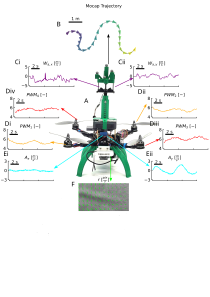

In [480]:
layout.append_figure_to_layer(layout.figures['fig_3'], 'fig_3', cleartarget=True)
layout.write_svg(input_svg)
display(SVG(input_svg))